<a href="https://colab.research.google.com/github/EinsteinAyo/New/blob/main/Full_PINN_Code_figures_final_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# East River PINN -- Complete Manuscript Figure Set: Generation Code

**Updated, complete version.** This notebook now reproduces the exact code
behind all 24 figures in `figures_final/`: the original 18 (12 core + 6
investigation-trail, Parts 1-3 below) plus the 5-figure, 3-way comparative
analysis added afterward (Part 4: tracer-informed PINN vs. hydrology-only
PINN vs. LSTM baseline, on a genuinely held-out split -- FINDINGS.md
Section 11). It is a notebook version of four batch scripts:
`pinn/make_plots_final.py` (core set), `pinn/make_plots_investigation_trail.py`
(investigation-trail set), `pinn/train_holdout.py` + `pinn/train_lstm_baseline.py`
(the held-out-split training scripts behind Part 4's checkpoints), and
`pinn/make_plots_comparative.py` (the comparative figures) -- split into
one logical cell per figure (or per training step) with a markdown
explanation before each.

**Checkpoints used, Parts 1-3 (core + investigation-trail):**
`results_meltlag_single` / `results_meltlag_split` -- the phase-partitioned,
melt-timing-lag-corrected weights, with the `C_f` concentration ceiling
applied **at inference only** via the current `model.py` (not retrained on
the ceiling). This is FINDINGS.md Section 9's final, cost-benefit-justified
recommendation.

**Checkpoints used, Part 4 (comparative analysis):** `results_comparative_tracer_single`,
`results_comparative_hydro_only`, `results_comparative_lstm`,
`results_comparative_lstm_small` -- all four trained from scratch under an
identical, fixed-seed 80/20 held-out split (`pinn/split.py`) built
specifically because the Parts 1-3 checkpoints were fit on 100% of the
data and can't be reused for a held-out comparison (FINDINGS.md Section
11.1). **Part 4's training cells are guarded by a `RUN_TRAINING` flag,
default `False`**: as shipped, this notebook loads the already-trained
checkpoints (fast, seconds) rather than reproducing ~70 minutes of CPU
training (~34 min per PINN variant, ~1 min per LSTM variant) on every
run. Set `RUN_TRAINING = True` in the cell below Part 4's introduction to
retrain everything from scratch instead.

**One deliberate deviation from the batch scripts**: the originals call
`matplotlib.use("Agg")` and `plt.close(fig)` after every figure, since they
run headless and write many PNGs in one pass. Here, both are omitted (and
`%matplotlib inline` is used instead) purely so each figure also displays
inline when you run the cell -- the figure-generation code itself,
including every `savefig(...)` call that writes the PNG + its `.md`
caption, is otherwise unchanged.

Run cells top to bottom. Requires the `pinn/` package on `sys.path` (adjust
`PINN_DIR` below if this notebook isn't inside the repo's `pinn/` folder),
and the checkpoints referenced to exist under the repo root (all are
already committed).

## Setup

Imports, path configuration, and the project's shared plotting style
(`style.py`): a fixed color palette (`C`), font sizes (`FONT`), 300 DPI /
`bbox_inches="tight"` save settings, and the canonical sub-basin order
(`Rustlers, Copper, EAQ, Gothic_ME, PH_LT`) that every figure in this set
uses. `apply_base_style()` applies the font-size rcParams globally.

`DATA_DIR` is the uploaded CLM/discharge/chloride/isotope data; `SPLIT_DIR`
/ `SINGLE_DIR` are the two recommended checkpoints; `OUT_DIR` is where core
figures + captions are written (`figures_final/core`). The assertion checks
that `ORDER` really does match `data.py`'s canonical sub-basin order before
any figure is built.

In [ ]:
%matplotlib inline
import json
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

PINN_DIR = "/home/user/New/pinn"
if PINN_DIR not in sys.path:
    sys.path.insert(0, PINN_DIR)

from data import load_dataset, SUBBASINS, UPSTREAM
from model import HydroPINN, SUB_IDX
from metrics import nse, kge, r2
from style import C, FONT, apply_base_style, savefig

DATA_DIR = "/home/user/New/uploaded_data"
# Current recommended checkpoint: results_meltlag_single/split, i.e. the
# melt-timing-lag-corrected, phase-partitioned weights WITHOUT the C_f-
# ceiling retrain -- the retrain (results_cfceiling_single/split) was
# tested and found to be a net regression on baseflow fraction and EAQ
# chloride vs. applying the C_f ceiling to these same weights at
# inference only (see README's "Recommendation reversed" section). The
# current model.py still has the C_f ceiling in code, so these figures
# already reflect it. See README for the full checkpoint history.
SPLIT_DIR = "/home/user/New/results_meltlag_split"
SINGLE_DIR = "/home/user/New/results_meltlag_single"
OUT_DIR = "/home/user/New/figures_final/core"

os.makedirs(OUT_DIR, exist_ok=True)
apply_base_style()

ORDER = ["Rustlers", "Copper", "EAQ", "Gothic_ME", "PH_LT"]
assert ORDER == SUBBASINS, "sub-basin order must match data.py's canonical order"

## Network routing helper

`route()` propagates any set of local (per-node) flow-component arrays
`[T, n_sub]` through the watershed's routed topology, matching `model.py`'s
own `Q_tot,j = Q_loc,j + sum_{u in U(j)} Q_tot,u` recursion
(`U(Gothic_ME)={Rustlers,Copper,EAQ}`, `U(PH_LT)={Gothic_ME}`). It's used
throughout both scripts to turn *local* generation (what each sub-basin
produces on its own) into the *routed* total a real gauge would measure.

In [ ]:
def route(local_dict):
    """Route local per-node arrays [T, n_sub] through U(j) like model.py's
    Qtot routing, for any set of components at once. Returns dict of the
    same keys, each now the ROUTED (local + all upstream) total."""
    routed = {k: v.copy() for k, v in local_dict.items()}
    for b in ORDER:
        j = SUB_IDX[b]
        for u in UPSTREAM[b]:
            ui = SUB_IDX[u]
            for k in routed:
                routed[k][:, j] = routed[k][:, j] + routed[k][:, ui]
    return routed

## Load data and run the split-C_in model's forward pass

Loads the full dataset (`load_dataset`), builds a fresh `HydroPINN` model,
loads the split-C_in checkpoint's weights, and runs one forward pass over
the full record using the phase-partitioned, melt-lag-shifted effective
water input `P_e,j(t)` (`d["pe_mm_day"]`, already `P_liquid,j + SM_j` with
the 10-day melt-timing-lag shift baked in by `data.py`) and `ET_j(t)`. This
single forward pass (`out`) is reused by every core figure below that needs
per-timestep model state (storages, flows, concentrations).

In [ ]:
d = load_dataset(DATA_DIR)
dates = d["dates"]
model = HydroPINN()
model.load_state_dict(torch.load(f"{SPLIT_DIR}/model.pt", map_location="cpu"))
model.eval()
precip = torch.tensor(d["pe_mm_day"])  # P_e,j = P_liquid,j + SM_j, the model's water-input argument
et = torch.tensor(d["et_mm_day"])
doy = torch.tensor(dates.dayofyear.values.astype(np.float32))
with torch.no_grad():
    out = model(precip, et, doy)

## Load saved predictions/metrics/history, derive routed flow components

Loads both variants' saved `predictions.npz` (obs/sim discharge + chloride
arrays used by the scatter and comparison figures) and `metrics.json`
(learned parameters, per-gauge fit statistics). Then pulls the forward
pass's per-node state (`Sf, Ss` storages; `Quf, Qf, Qs` flow components;
`Qtot`; `f_uf, f_f` partition fractions), converts flows from mm/day to
m^3/s via `model.area_cms`, and routes the fast/slow components through
the network with `route()` to get `fast_frac_routed` / `baseflow_frac_routed`
-- the ROUTED fractions that a real gauge measurement corresponds to. The
assertion cross-checks that the routed components sum back to the model's
own `Qtot_vol` output to float precision.

In [ ]:
single_npz = np.load(f"{SINGLE_DIR}/predictions.npz", allow_pickle=True)
split_npz = np.load(f"{SPLIT_DIR}/predictions.npz", allow_pickle=True)
with open(f"{SINGLE_DIR}/metrics.json") as f:
    single_info = json.load(f)
with open(f"{SPLIT_DIR}/metrics.json") as f:
    split_info = json.load(f)

Sf = out["Sf"].numpy(); Ss = out["Ss"].numpy()
Quf = out["Quf"].numpy(); Qf = out["Qf"].numpy(); Qs = out["Qs"].numpy()
Qtot = out["Qtot_vol"].numpy()
f_uf = out["f_uf"].numpy(); f_f = out["f_f"].numpy()

area_cms = model.area_cms.numpy()  # mm/day -> m^3/s per node, same factor model.py uses
Quf_vol, Qf_vol, Qs_vol = Quf * area_cms, Qf * area_cms, Qs * area_cms
routed = route({"Quf": Quf_vol.copy(), "Qf": Qf_vol.copy(), "Qs": Qs_vol.copy()})
Quf_tot, Qf_tot, Qs_tot = routed["Quf"], routed["Qf"], routed["Qs"]
fast_frac_routed = (Quf_tot + Qf_tot) / np.clip(Quf_tot + Qf_tot + Qs_tot, 1e-9, None)
baseflow_frac_routed = Qs_tot / np.clip(Quf_tot + Qf_tot + Qs_tot, 1e-9, None)
# sanity: Qs_tot/(Quf_tot+Qf_tot+Qs_tot) should equal Qs_tot/Qtot to float precision
assert np.allclose(Quf_tot + Qf_tot + Qs_tot, Qtot, atol=1e-6), "routed components must sum to Qtot"

fast_frac_local = (Quf + Qf) / np.clip(Quf + Qf + Qs, 1e-9, None)

## Figure 1 -- Loss curves (log scale)

Plots total loss and its two data-fit components (`q_loss` = discharge,
`cl_loss` = chloride; the smoothness and storage-barrier regularizer terms
are small by comparison and omitted for readability) over 1000 training
epochs, for both model variants, read from each checkpoint's
`history.json`. This documents training convergence for the exact
checkpoint recommended in FINDINGS.md Section 9.

wrote /home/user/New/figures_final/core/01_loss_curves.png


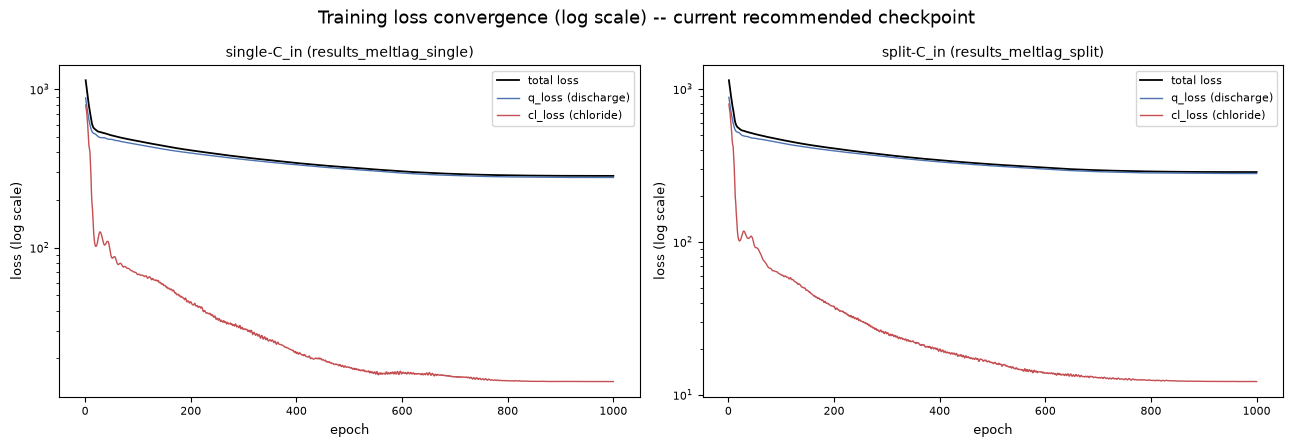

In [ ]:
with open(f"{SINGLE_DIR}/history.json") as f:
    single_hist = json.load(f)
with open(f"{SPLIT_DIR}/history.json") as f:
    split_hist = json.load(f)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, hist, label, color in [
    (axes[0], single_hist, "single-C_in", C["single"]),
    (axes[1], split_hist, "split-C_in", C["split"]),
]:
    epochs = [h["epoch"] for h in hist]
    ax.plot(epochs, [h["loss"] for h in hist], color="black", lw=1.3, label="total loss")
    ax.plot(epochs, [h["q_loss"] for h in hist], color=C["single"], lw=1.0, label="q_loss (discharge)")
    ax.plot(epochs, [h["cl_loss"] for h in hist], color=C["highlight"], lw=1.0, label="cl_loss (chloride)")
    ax.set_yscale("log")
    ax.set_xlabel("epoch")
    ax.set_ylabel("loss (log scale)")
    ax.set_title(f"{label} ({SINGLE_DIR.split('/')[-1] if 'single' in label else SPLIT_DIR.split('/')[-1]})",
                 fontsize=FONT["title"])
    ax.legend(fontsize=FONT["legend"])
fig.suptitle("Training loss convergence (log scale) -- current recommended checkpoint")
fig.tight_layout()
savefig(fig, f"{OUT_DIR}/01_loss_curves.png", f"""
**Training loss convergence, log scale.** Total loss and its two data
components (`q_loss` = discharge, `cl_loss` = chloride; the smoothness
and storage-barrier regularizer terms are small by comparison and
omitted for readability -- see `results_meltlag_*/history.json` for the
full per-epoch breakdown) over 1000 training epochs, both model
variants. This is the checkpoint recommended in `FINDINGS.md` Section 9
-- `results_meltlag_single`/`results_meltlag_split`, phase-partitioned
`P_e` with the 10-day melt-timing-lag correction, evaluated here (and in
every other figure in this set) with the `C_f` ceiling applied via the
current `model.py` at inference (Section 9's reversed recommendation:
the retrained `C_f`-ceiling checkpoint was tested and rejected in favor
of applying the ceiling to these weights without retraining).
Final losses: single-C_in {single_hist[-1]['loss']:.1f} (q={single_hist[-1]['q_loss']:.1f},
cl={single_hist[-1]['cl_loss']:.1f}); split-C_in {split_hist[-1]['loss']:.1f}
(q={split_hist[-1]['q_loss']:.1f}, cl={split_hist[-1]['cl_loss']:.1f}).
""")

## Figure 12 -- CLM forcing overview (phase-partitioned precip + ET)

Shows the effective water input `P_e,j(t) = P_liquid,j(t) + SM_j(t)` per
sub-basin: raw CLM precipitation (grey, background reference), split into
`P_liquid` (blue, passes through unchanged) and precip withheld entirely on
SNOTEL-confirmed snow days (later released as `SM`, red, on the day SWE
actually declines, per the melt-timing-lag-shifted `data.py` pipeline).
`ET_j(t)` is overlaid on a secondary axis. This is generated here, out of
numeric order, because it only needs the raw `d` dataset already loaded
above, matching the original script's structure.

wrote /home/user/New/figures_final/core/12_forcing_overview.png


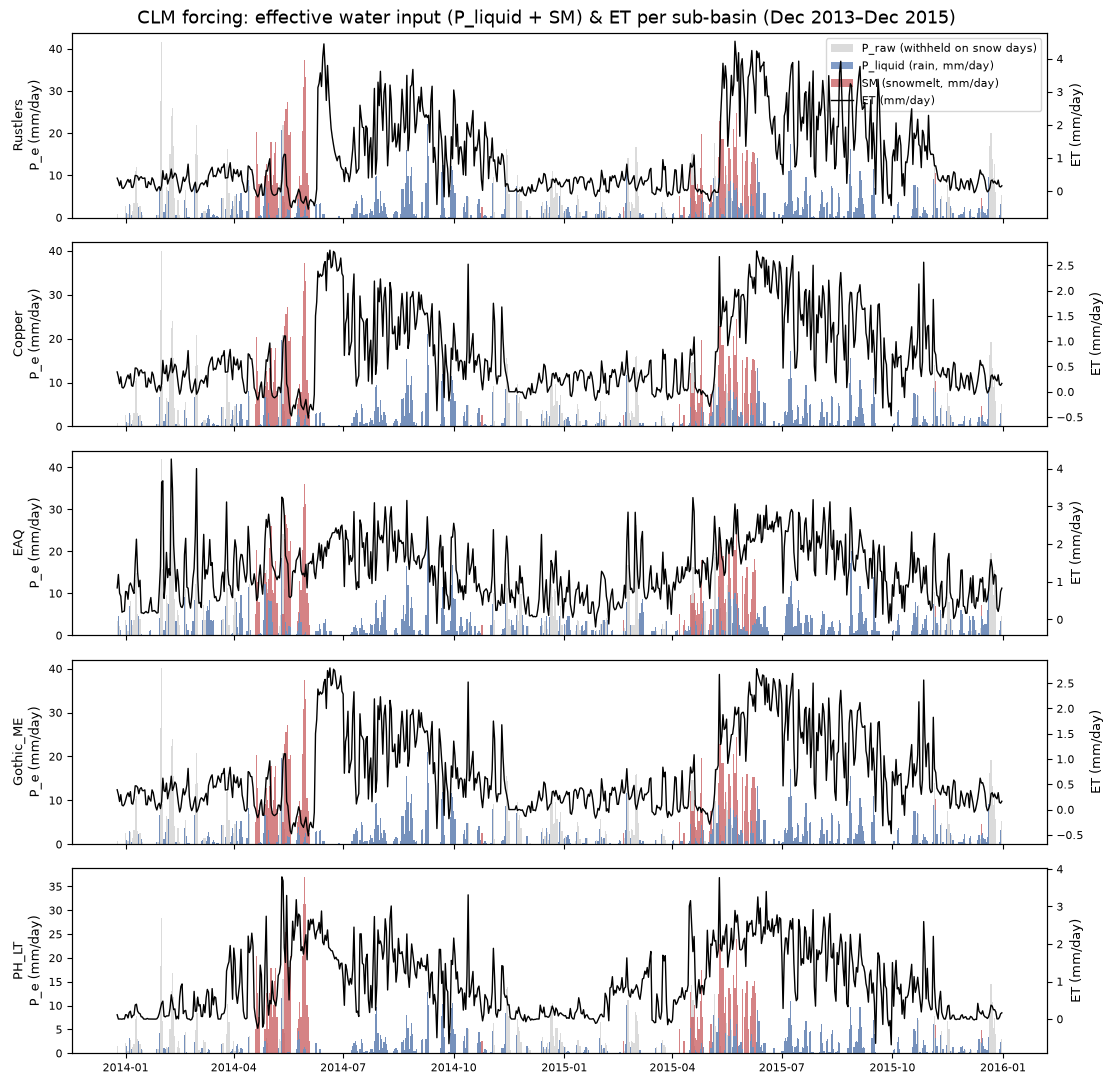

In [ ]:
fig, axes = plt.subplots(len(ORDER), 1, figsize=(11, 2.2 * len(ORDER)), sharex=True)
for i, b in enumerate(ORDER):
    ax = axes[i]
    ax2 = ax.twinx()
    ax.bar(dates, d["precip_mm_day"][:, i], width=1.0, color="#999999", alpha=0.35,
           label="P_raw (withheld on snow days)")
    ax.bar(dates, d["precip_liquid_mm_day"][:, i], width=1.0, color=C["single"], alpha=0.7,
           label="P_liquid (rain, mm/day)")
    ax.bar(dates, d["snowmelt_mm_day"][:, i], width=1.0, bottom=d["precip_liquid_mm_day"][:, i],
           color=C["highlight"], alpha=0.7, label="SM (snowmelt, mm/day)")
    ax2.plot(dates, d["et_mm_day"][:, i], color="black", lw=1.0, label="ET (mm/day)")
    ax.set_ylabel(f"{b}\nP_e (mm/day)")
    ax2.set_ylabel("ET (mm/day)", color="black")
    ax2.tick_params(axis="y", labelcolor="black")
    if i == 0:
        l1, lb1 = ax.get_legend_handles_labels(); l2, lb2 = ax2.get_legend_handles_labels()
        ax.legend(l1 + l2, lb1 + lb2, loc="upper right")
fig.suptitle("CLM forcing: effective water input (P_liquid + SM) & ET per sub-basin (Dec 2013–Dec 2015)")
fig.tight_layout()
savefig(fig, f"{OUT_DIR}/12_forcing_overview.png", """
**Forcing data overview.** Effective water input `P_e,j(t) = P_liquid,j(t) +
SM_j(t)`: raw CLM precipitation `P_raw,j` (grey, background reference only)
is phase-partitioned into `P_liquid,j` (blue, passes through unchanged) and
withheld entirely on days the Butte SNOTEL 380 record shows SWE increasing
(rain/snow phase-partitioning fix -- a day's precip doesn't count as both
immediate liquid input and, later, snowmelt), released later as `SM_j`
(red, day-to-day SWE decline) on whatever day SWE actually drops. Single-
station series applied to all 5 sub-basins. `ET_j(t)` (Section 2 of the
doc) also shown for each of the 5 modeled nodes, over the full CLM
coverage window used for training.
""")

## Figure 2 -- Storage dynamics (log scale)

Plots `S_f,j(t)` and `S_s,j(t)` for each sub-basin on a log axis (rather
than linear) so `S_s`'s dynamics remain visible instead of being flattened
against `S_f`'s larger range. Both storages are clamped at the model's
internal numerical floor (1e-6 mm) before plotting.

wrote /home/user/New/figures_final/core/02_storage_dynamics.png


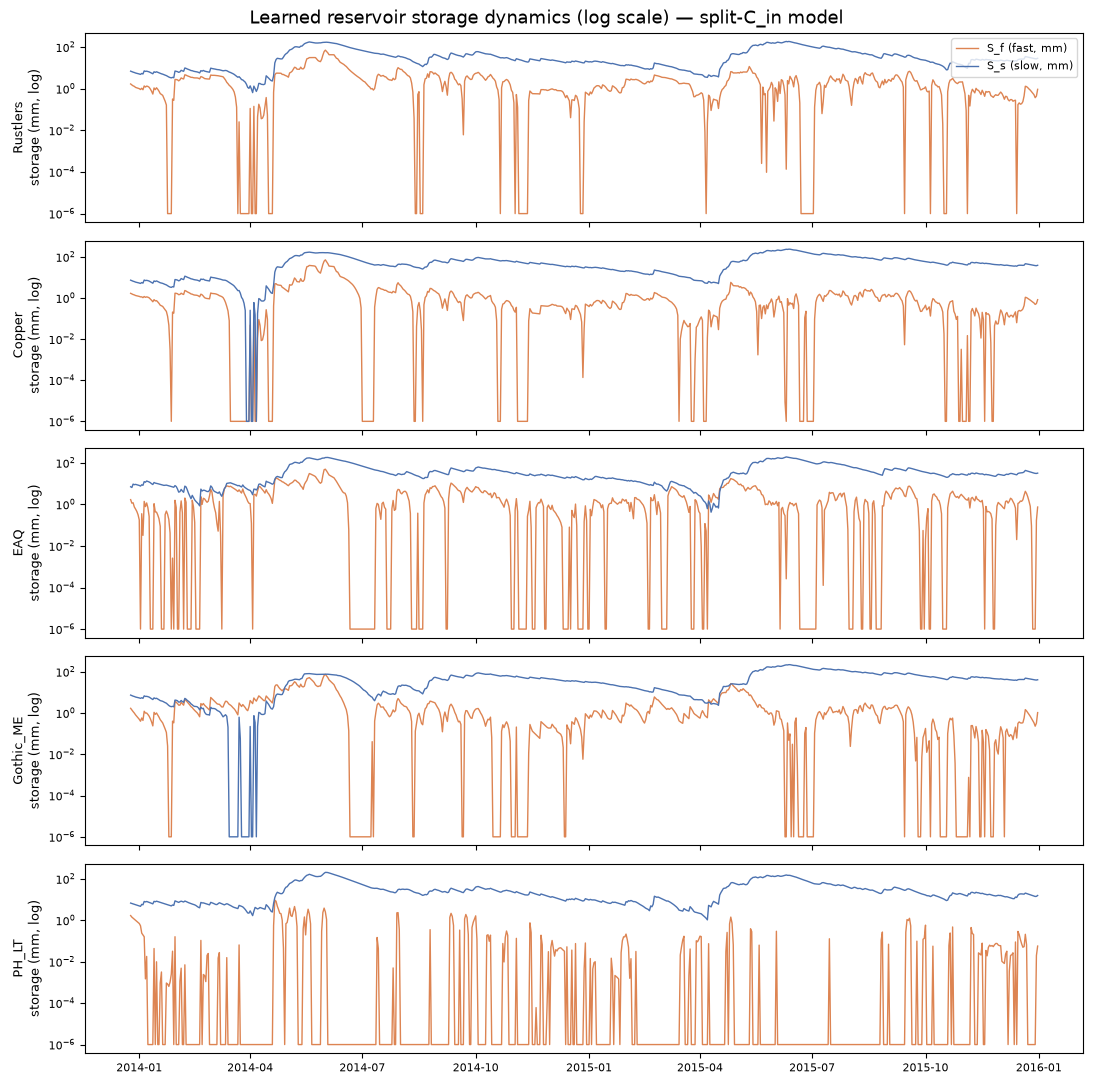

In [ ]:
fig, axes = plt.subplots(len(ORDER), 1, figsize=(11, 2.2 * len(ORDER)), sharex=True)
for i, b in enumerate(ORDER):
    ax = axes[i]
    ax.plot(dates, np.clip(Sf[:, i], 1e-6, None), color=C["Sf"], lw=1.0, label="S_f (fast, mm)")
    ax.plot(dates, np.clip(Ss[:, i], 1e-6, None), color=C["Ss"], lw=1.0, label="S_s (slow, mm)")
    ax.set_yscale("log")
    ax.set_ylabel(f"{b}\nstorage (mm, log)")
    if i == 0:
        ax.legend(loc="upper right")
fig.suptitle("Learned reservoir storage dynamics (log scale) — split-C_in model")
fig.tight_layout()
savefig(fig, f"{OUT_DIR}/02_storage_dynamics.png", """
**Storage dynamics, log scale.** `S_f,j(t)` and `S_s,j(t)` (Section 5.3 of
the formulation doc) for each sub-basin. Log scale (vs. the earlier linear
version) so `S_s` is visible rather than flattened against `S_f`'s larger
range -- both storages are clamped at an internal floor of 1e-6 mm
(numerical safeguard, not a physical zero) and plotted from that floor.
See `09_storage_floor_diagnostic.png` for how often each reservoir
actually sits at that floor.
""")

## Figure 3 -- Fast/slow flow partitioning (local generation)

Left column: stacked local flow components (`Q_uf, Q_f, Q_s`) per
sub-basin. Right column: the daily local fast-flow fraction
`(Q_uf+Q_f)/Q_loc`, shown both as the raw (flickering) daily signal and a
7-day centered rolling mean, so the underlying seasonal pattern is visible
through the day-to-day noise. This is **local** generation only -- Figure 8
below shows the **routed** total each gauge actually measures.

wrote /home/user/New/figures_final/core/03_flow_partitioning.png


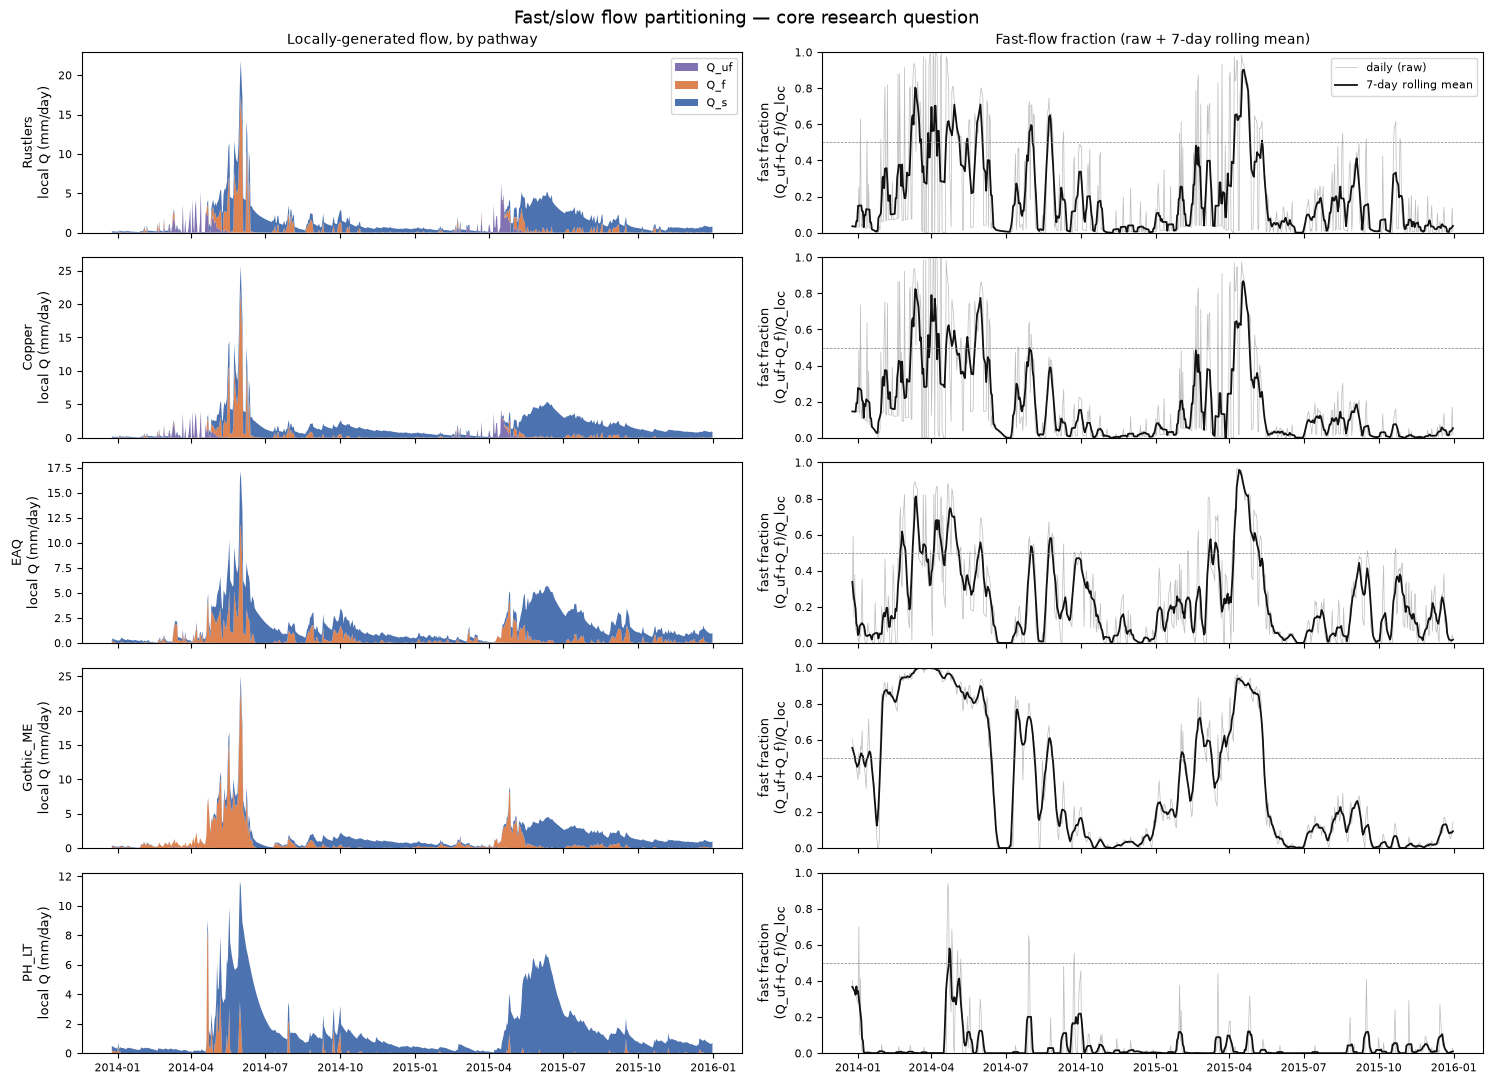

In [ ]:
fig, axes = plt.subplots(len(ORDER), 2, figsize=(15, 2.2 * len(ORDER)), sharex="col")
for i, b in enumerate(ORDER):
    ax_stack, ax_frac = axes[i, 0], axes[i, 1]
    ax_stack.stackplot(dates, Quf[:, i], Qf[:, i], Qs[:, i],
                        colors=[C["Quf"], C["Qf"], C["Qs"]],
                        labels=["Q_uf", "Q_f", "Q_s"])
    ax_stack.set_ylabel(f"{b}\nlocal Q (mm/day)")

    raw = pd.Series(fast_frac_local[:, i], index=dates)
    roll = raw.rolling(7, center=True, min_periods=1).mean()
    ax_frac.plot(raw.index, raw.values, color="#bbbbbb", lw=0.5, label="daily (raw)")
    ax_frac.plot(roll.index, roll.values, color="#111111", lw=1.3, label="7-day rolling mean")
    ax_frac.set_ylim(0, 1)
    ax_frac.set_ylabel("fast fraction\n(Q_uf+Q_f)/Q_loc")
    ax_frac.axhline(0.5, color="gray", lw=0.5, ls="--")
    if i == 0:
        ax_stack.legend(loc="upper right"); ax_stack.set_title("Locally-generated flow, by pathway")
        ax_frac.legend(loc="upper right"); ax_frac.set_title("Fast-flow fraction (raw + 7-day rolling mean)")
fig.suptitle("Fast/slow flow partitioning — core research question")
fig.tight_layout()
savefig(fig, f"{OUT_DIR}/03_flow_partitioning.png", """
**Fast/slow flow partitioning, local generation.** Left: stacked local
flow components (`Q_uf`, `Q_f`, `Q_s`) per sub-basin. Right: the daily
fast-flow fraction `(Q_uf+Q_f)/Q_loc` (thin gray) with a 7-day centered
rolling mean overlaid (thick black) so the underlying seasonal signal is
visible through the day-to-day flicker -- the flicker itself is a known
model limitation (documented in the README): the partition network
re-decides `f_uf,j(t)`/`f_f,j(t)` independently each day with no
smoothness penalty. This is **local** generation only; see
`08_baseflow_fraction_validation.png` for the **routed** total at each
gauge, which is what the Hubbard-et-al.-style benchmark applies to.
""")

## Figure 4 -- Learned physical parameters by sub-basin

A 2x3 grid of bar charts comparing, across all 5 sub-basins and both model
variants: `K_f,j(t)`'s two learned bounds (`K_f,recession` for dry periods,
`K_f,storm` for storm response -- `K_f` is covariate-dependent rather than a
single constant, motivated by the recession-curve mismatch in Figure 13
below), the slow-reservoir constant `K_s`, `alpha_ET` (fraction of ET drawn
from the fast reservoir), the chloride end-member(s) `C_in`, and `b`
(the `P_e` threshold in `K_f,j(t)`'s sigmoid transition).

wrote /home/user/New/figures_final/core/04_learned_parameters.png


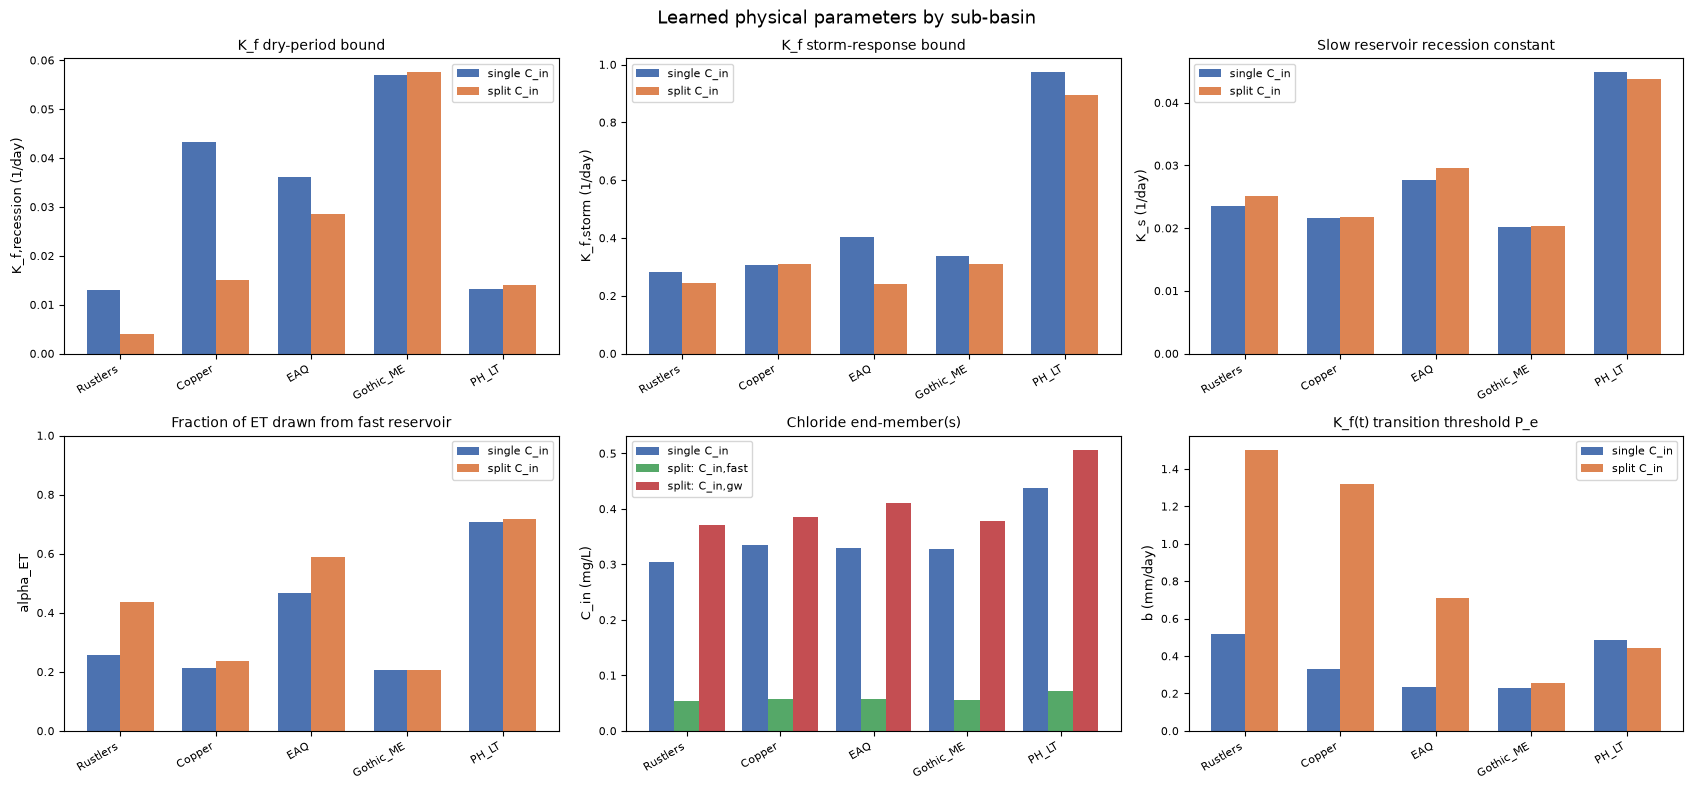

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(17, 8))
x = np.arange(len(ORDER))
width = 0.35

Kfrec_single = [single_info["params"][b]["Kf_recession_perday"] for b in ORDER]
Kfrec_split = [split_info["params"][b]["Kf_recession_perday"] for b in ORDER]
Kfstorm_single = [single_info["params"][b]["Kf_storm_perday"] for b in ORDER]
Kfstorm_split = [split_info["params"][b]["Kf_storm_perday"] for b in ORDER]
Ks_single = [single_info["params"][b]["Ks_perday"] for b in ORDER]
Ks_split = [split_info["params"][b]["Ks_perday"] for b in ORDER]
alphaET_single = [single_info["params"][b]["alphaET"] for b in ORDER]
alphaET_split = [split_info["params"][b]["alphaET"] for b in ORDER]

ax = axes[0, 0]
ax.bar(x - width/2, Kfrec_single, width, label="single C_in", color=C["single"])
ax.bar(x + width/2, Kfrec_split, width, label="split C_in", color=C["split"])
ax.set_xticks(x); ax.set_xticklabels(ORDER, rotation=30, ha="right")
ax.set_ylabel("K_f,recession (1/day)"); ax.set_title("K_f dry-period bound"); ax.legend()

ax = axes[0, 1]
ax.bar(x - width/2, Kfstorm_single, width, label="single C_in", color=C["single"])
ax.bar(x + width/2, Kfstorm_split, width, label="split C_in", color=C["split"])
ax.set_xticks(x); ax.set_xticklabels(ORDER, rotation=30, ha="right")
ax.set_ylabel("K_f,storm (1/day)"); ax.set_title("K_f storm-response bound"); ax.legend()

ax = axes[0, 2]
ax.bar(x - width/2, Ks_single, width, label="single C_in", color=C["single"])
ax.bar(x + width/2, Ks_split, width, label="split C_in", color=C["split"])
ax.set_xticks(x); ax.set_xticklabels(ORDER, rotation=30, ha="right")
ax.set_ylabel("K_s (1/day)"); ax.set_title("Slow reservoir recession constant"); ax.legend()

ax = axes[1, 0]
ax.bar(x - width/2, alphaET_single, width, label="single C_in", color=C["single"])
ax.bar(x + width/2, alphaET_split, width, label="split C_in", color=C["split"])
ax.set_xticks(x); ax.set_xticklabels(ORDER, rotation=30, ha="right")
ax.set_ylabel("alpha_ET"); ax.set_title("Fraction of ET drawn from fast reservoir")
ax.legend(); ax.set_ylim(0, 1)

ax = axes[1, 1]
Cin_single = [single_info["params"][b]["Cin_mgL"] for b in ORDER]
Cin_fast = [split_info["params"][b]["Cin_fast_mgL"] for b in ORDER]
Cin_gw = [split_info["params"][b]["Cin_gw_mgL"] for b in ORDER]
w3 = 0.27
ax.bar(x - w3, Cin_single, w3, label="single C_in", color=C["single"])
ax.bar(x, Cin_fast, w3, label="split: C_in,fast", color=C["Cin_fast"])
ax.bar(x + w3, Cin_gw, w3, label="split: C_in,gw", color=C["Cin_gw"])
ax.set_xticks(x); ax.set_xticklabels(ORDER, rotation=30, ha="right")
ax.set_ylabel("C_in (mg/L)"); ax.set_title("Chloride end-member(s)"); ax.legend()

ax = axes[1, 2]
Kfb_single = [single_info["params"][b]["Kf_b_mm"] for b in ORDER]
Kfb_split = [split_info["params"][b]["Kf_b_mm"] for b in ORDER]
ax.bar(x - width/2, Kfb_single, width, label="single C_in", color=C["single"])
ax.bar(x + width/2, Kfb_split, width, label="split C_in", color=C["split"])
ax.set_xticks(x); ax.set_xticklabels(ORDER, rotation=30, ha="right")
ax.set_ylabel("b (mm/day)"); ax.set_title("K_f(t) transition threshold P_e"); ax.legend()

fig.suptitle("Learned physical parameters by sub-basin")
fig.tight_layout()
savefig(fig, f"{OUT_DIR}/04_learned_parameters.png", """
**Learned physical parameters.** `K_f,j(t)`'s two learned bounds
(`K_f,recession,j`, dry-period; `K_f,storm,j`, storm-response -- see
README for why K_f became covariate-dependent instead of a single
constant), `K_s,j`, `alpha_ET,j` (ET fast/slow split), the chloride
end-member(s) `C_in,j`, and `b_j` (the P_e threshold in K_f,j(t)'s
sigmoid transition) -- compared across the 5 sub-basins and between the
single- and split-C_in model variants.
""")

## Figures 5a/5b -- Observed vs. simulated scatter, with NSE/KGE/R2

`scatter_fig()` builds a 2 x 5 grid (discharge on top, chloride on bottom,
one column per gauge) of observed-vs-simulated scatter plots with a 1:1
reference line, annotating each panel with NSE, KGE (Kling-Gupta
Efficiency), and R^2 computed on the same finite obs/sim pairs used in
`metrics.json`. Called once per model variant, producing two separate
figures (5a: single-C_in, 5b: split-C_in) since the review asked for both
variants shown explicitly rather than picking one.

wrote /home/user/New/figures_final/core/05a_scatter_obs_vs_sim_single_Cin.png


wrote /home/user/New/figures_final/core/05b_scatter_obs_vs_sim_split_Cin.png


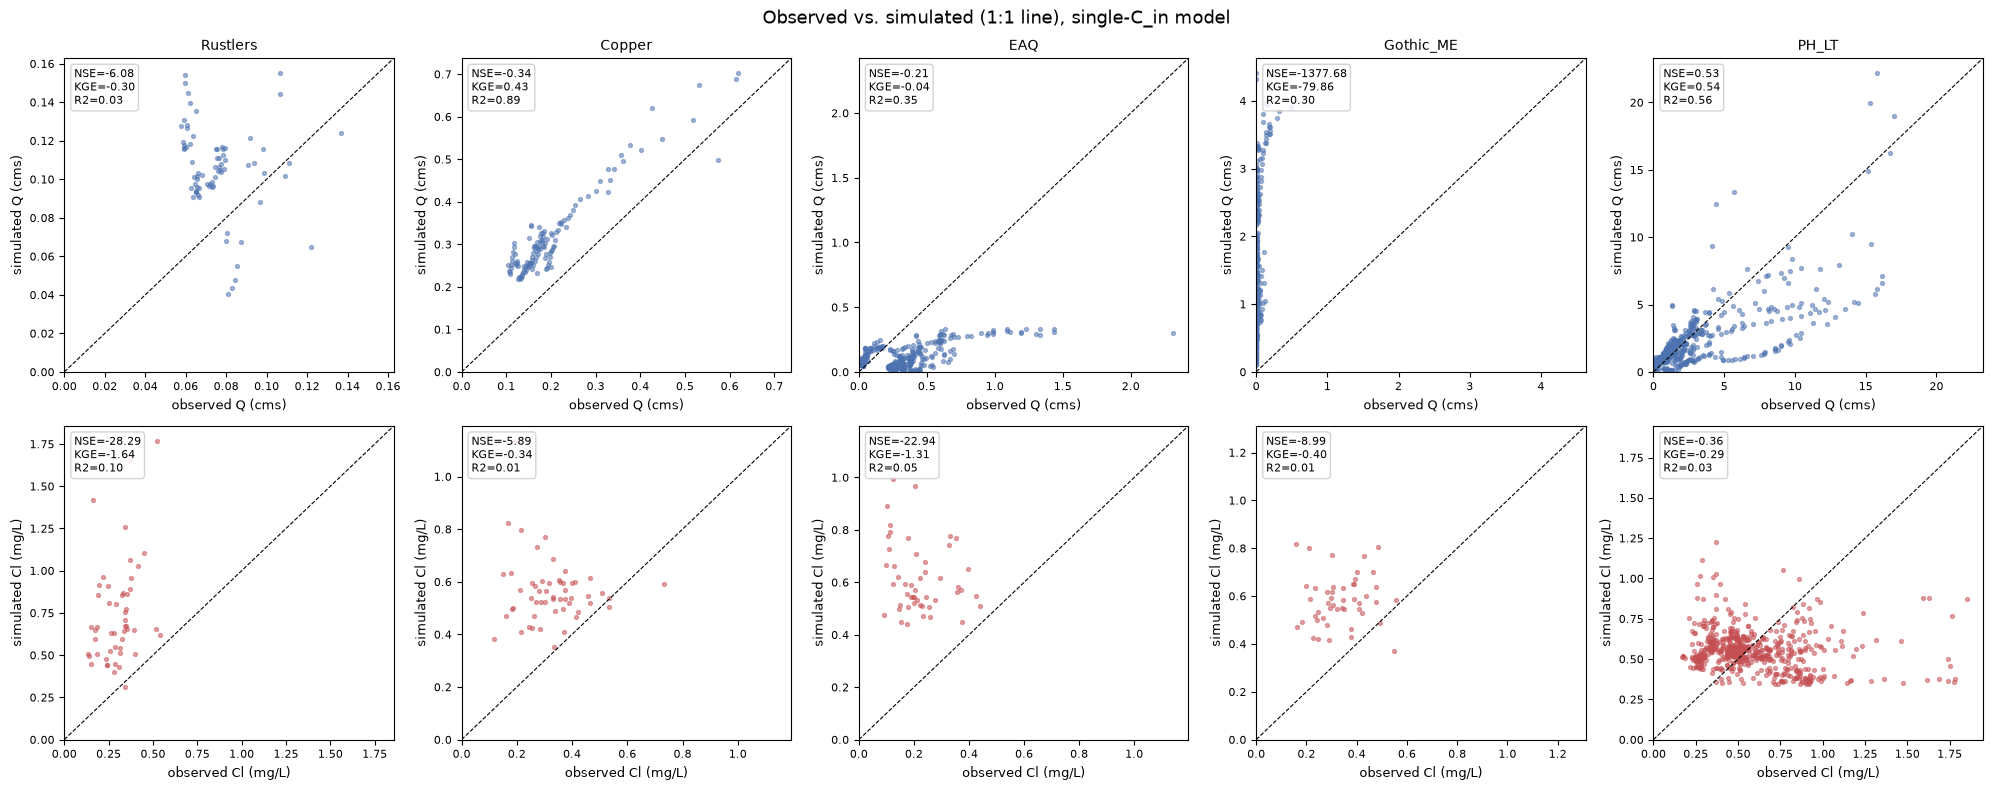

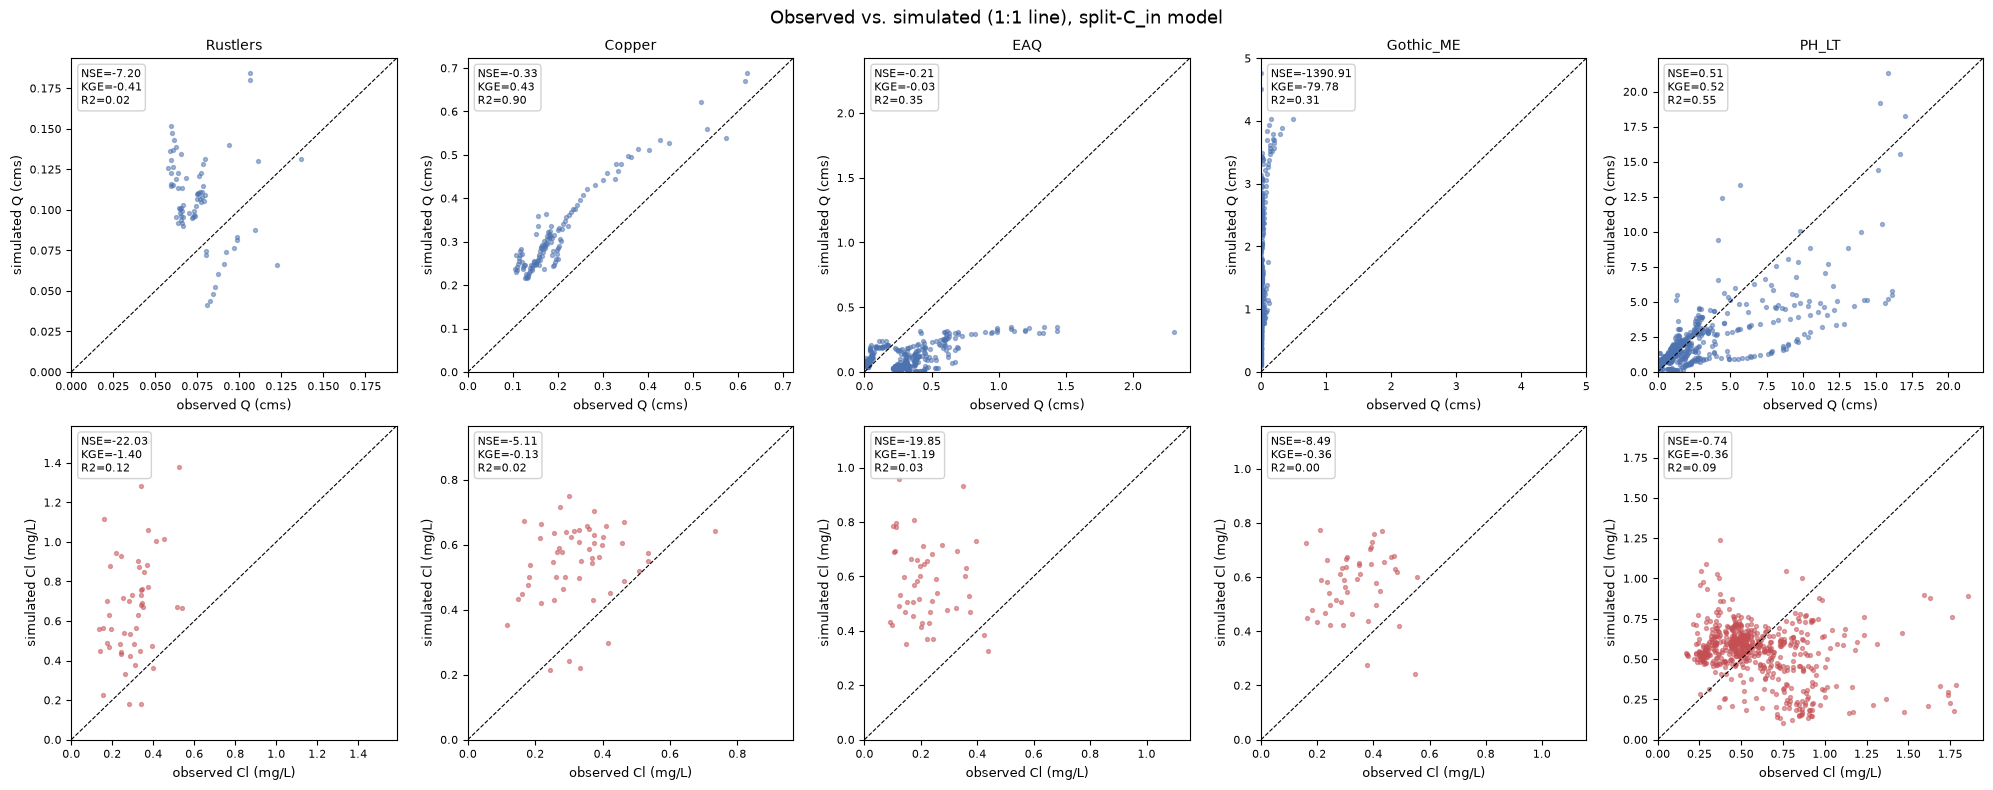

In [ ]:
def scatter_fig(npz, model_name, filename):
    fig, axes = plt.subplots(2, len(ORDER), figsize=(4 * len(ORDER), 8))
    for i, b in enumerate(ORDER):
        q_o, q_p = npz["q_obs"][:, i], npz["q_pred"][:, i]
        cl_o, cl_p = npz["cl_obs"][:, i], npz["cl_pred"][:, i]

        ax = axes[0, i]
        m = np.isfinite(q_o)
        ax.scatter(q_o[m], q_p[m], s=8, alpha=0.5, color=C["single"])
        lim = [0, max(np.nanmax(q_o), np.nanmax(q_p[m])) * 1.05] if m.sum() else [0, 1]
        ax.plot(lim, lim, "k--", lw=0.8)
        ax.set_xlim(lim); ax.set_ylim(lim)
        txt = f"NSE={nse(q_o,q_p):.2f}\nKGE={kge(q_o,q_p):.2f}\nR2={r2(q_o,q_p):.2f}"
        ax.text(0.03, 0.97, txt, transform=ax.transAxes, va="top", fontsize=FONT["annot"],
                bbox=dict(boxstyle="round", fc="white", ec="#ccc", alpha=0.85))
        ax.set_title(b, fontsize=FONT["title"])
        ax.set_xlabel("observed Q (cms)"); ax.set_ylabel("simulated Q (cms)")

        ax = axes[1, i]
        m = np.isfinite(cl_o)
        ax.scatter(cl_o[m], cl_p[m], s=8, alpha=0.5, color=C["highlight"])
        lim = [0, max(np.nanmax(cl_o), np.nanmax(cl_p[m])) * 1.05] if m.sum() else [0, 1]
        ax.plot(lim, lim, "k--", lw=0.8)
        ax.set_xlim(lim); ax.set_ylim(lim)
        txt = f"NSE={nse(cl_o,cl_p):.2f}\nKGE={kge(cl_o,cl_p):.2f}\nR2={r2(cl_o,cl_p):.2f}"
        ax.text(0.03, 0.97, txt, transform=ax.transAxes, va="top", fontsize=FONT["annot"],
                bbox=dict(boxstyle="round", fc="white", ec="#ccc", alpha=0.85))
        ax.set_xlabel("observed Cl (mg/L)"); ax.set_ylabel("simulated Cl (mg/L)")

    fig.suptitle(f"Observed vs. simulated (1:1 line), {model_name} model")
    fig.tight_layout()
    savefig(fig, filename, f"""
**Goodness-of-fit scatter, {model_name} model.** Observed vs. simulated
discharge (top row) and chloride (bottom row) at all 5 gauges, 1:1 line
for reference. Each panel reports NSE, KGE (Kling-Gupta Efficiency), and
R^2 computed on the same finite obs/sim pairs used in `metrics.json`.
""")
    return fig

fig_5a = scatter_fig(single_npz, "single-C_in", f"{OUT_DIR}/05a_scatter_obs_vs_sim_single_Cin.png")
fig_5b = scatter_fig(split_npz, "split-C_in", f"{OUT_DIR}/05b_scatter_obs_vs_sim_split_Cin.png")

## Figure 7 -- Evapoconcentration check

Tests a specific, testable prediction: since ET removes water but not
chloride mass, simulated `C_tot` should rise during high-ET, low-flow
periods. Each point is one simulated day, colored by simulated `Q_tot`
(yellow = low flow). Generated here, before Figure 6, matching the
original script's order (it only needs the forward-pass `out` and doesn't
depend on the outlet-comparison figure).

wrote /home/user/New/figures_final/core/07_evapoconcentration.png


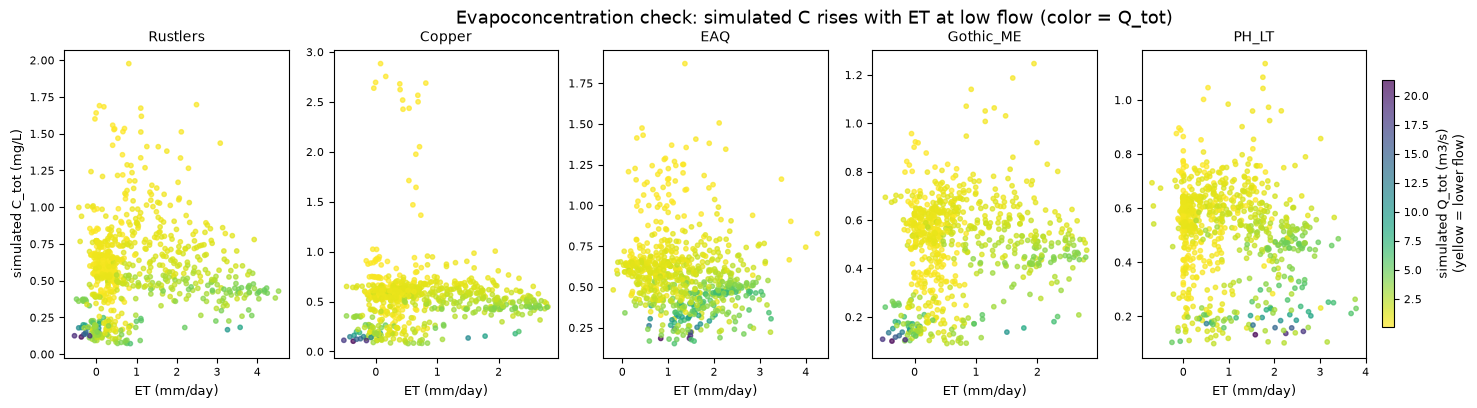

In [ ]:
fig, axes = plt.subplots(1, len(ORDER), figsize=(4 * len(ORDER), 4))
Ctot = out["Ctot"].numpy()
for i, b in enumerate(ORDER):
    ax = axes[i]
    sc = ax.scatter(d["et_mm_day"][:, i], Ctot[:, i], c=Qtot[:, i], s=10, cmap="viridis_r", alpha=0.7)
    ax.set_xlabel("ET (mm/day)")
    if i == 0:
        ax.set_ylabel("simulated C_tot (mg/L)")
    ax.set_title(b, fontsize=FONT["title"])
cbar = fig.colorbar(sc, ax=axes, shrink=0.8, pad=0.01)
cbar.set_label("simulated Q_tot (m3/s)\n(yellow = lower flow)")
fig.suptitle("Evapoconcentration check: simulated C rises with ET at low flow (color = Q_tot)")
savefig(fig, f"{OUT_DIR}/07_evapoconcentration.png", """
**Evapoconcentration check.** Doc Section 2's specific, testable
prediction: because ET removes water but not chloride mass, predicted
`C_f`/`C_s` (and hence `C_tot`) should rise during high-ET, low-flow
periods. Each point is one simulated day; color encodes simulated
`Q_tot` (yellow = low flow). The visible rise in scatter density/height
at higher ET, concentrated in the yellow (low-flow) points, is the
predicted signature -- though see `09_storage_floor_diagnostic.png` for
how much of the tallest spikes are the routing-floor artifact rather than
a physically meaningful evapoconcentration signal.
""", bbox_inches="tight")

## Figure 6 -- Single vs. split C_in model comparison at the outlet

Compares the two model variants' simulated discharge and chloride at the
watershed outlet (PH_LT) against observed data, over the full record.

wrote /home/user/New/figures_final/core/06_model_comparison_outlet.png


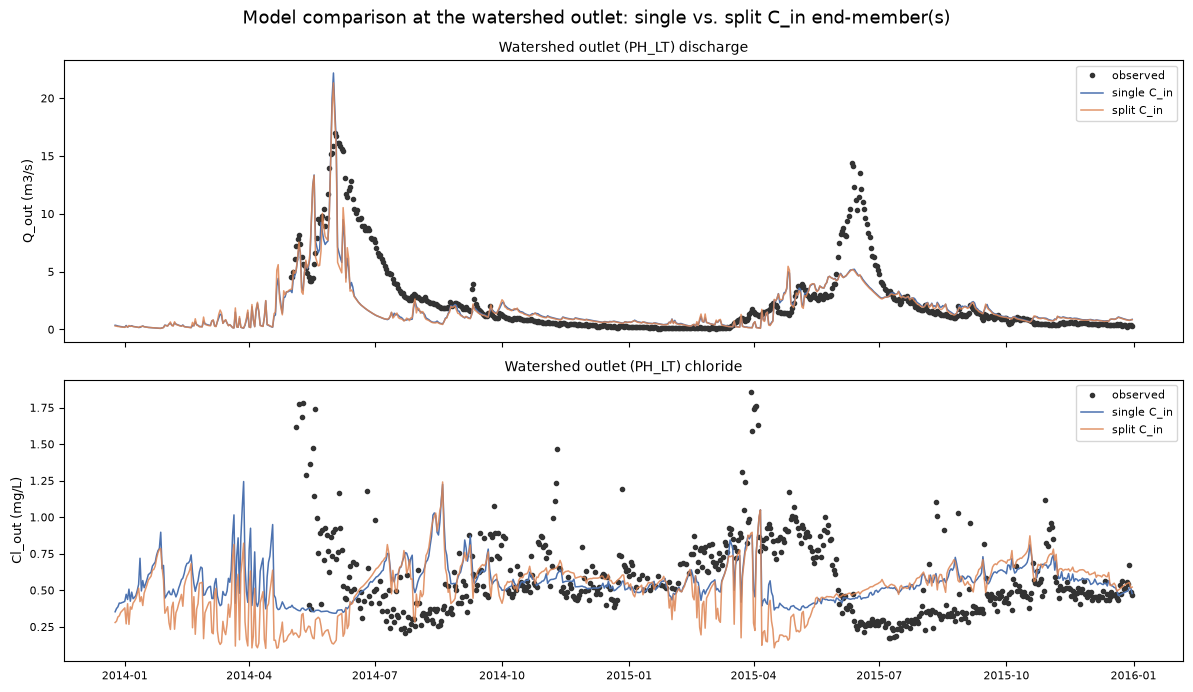

In [ ]:
j = ORDER.index("PH_LT")
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
ax = axes[0]
ax.plot(dates, single_npz["q_obs"][:, j], "o", ms=3, color=C["obs"], label="observed")
ax.plot(dates, single_npz["q_pred"][:, j], "-", lw=1.1, color=C["single"], label="single C_in")
ax.plot(dates, split_npz["q_pred"][:, j], "-", lw=1.1, color=C["split"], alpha=0.85, label="split C_in")
ax.set_ylabel("Q_out (m3/s)"); ax.set_title("Watershed outlet (PH_LT) discharge")
ax.legend()

ax = axes[1]
ax.plot(dates, single_npz["cl_obs"][:, j], "o", ms=3, color=C["obs"], label="observed")
ax.plot(dates, single_npz["cl_pred"][:, j], "-", lw=1.1, color=C["single"], label="single C_in")
ax.plot(dates, split_npz["cl_pred"][:, j], "-", lw=1.1, color=C["split"], alpha=0.85, label="split C_in")
ax.set_ylabel("Cl_out (mg/L)"); ax.set_title("Watershed outlet (PH_LT) chloride")
ax.legend()

fig.suptitle("Model comparison at the watershed outlet: single vs. split C_in end-member(s)")
fig.tight_layout()
savefig(fig, f"{OUT_DIR}/06_model_comparison_outlet.png", """
**Single- vs split-C_in comparison at the outlet.** `Q_out(t)` and
`C_out^model(t)` (Section 5.5) for both model variants against observed
Pumphouse/Lower-Triangle data.
""")

## Figure 8 -- Baseflow fraction validation

Plots the ROUTED slow-reservoir fraction `Q_s,tot,j(t)/Q_tot,j(t)` at each
gauge against a benchmark band the user supplied as Hubbard et al. (2018):
12-33% mean annual, 17-50% during a "baseflow period" -- defined here as
winter (Dec-Mar), a modeling choice for this snowmelt-dominated catchment,
not a value from the source. **Note**: this session has not independently
verified the Hubbard et al. citation; the band is plotted exactly as
user-supplied.

wrote /home/user/New/figures_final/core/08_baseflow_fraction_validation.png


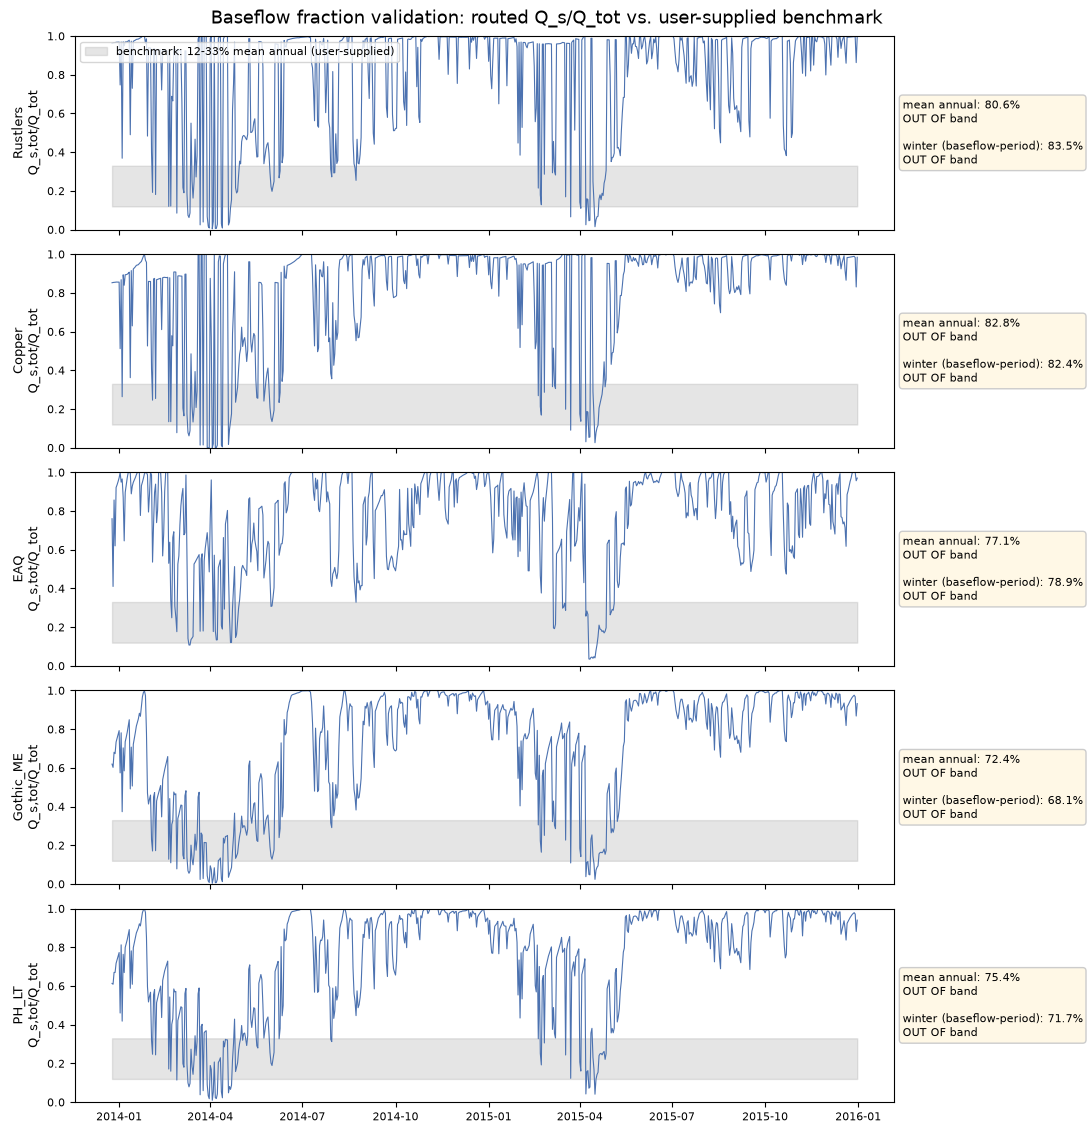

In [ ]:
HUBBARD_ANNUAL = (0.12, 0.33)
HUBBARD_BASEFLOW_PERIOD = (0.17, 0.50)
# Baseflow period defined here as winter (Dec-Mar): snow-covered, no active
# melt, flow dominated by recession -- standard for a snowmelt catchment
# like this one. This is a modeling choice, not a value from the doc.
winter_mask = dates.month.isin([12, 1, 2, 3])

fig, axes = plt.subplots(len(ORDER), 1, figsize=(11, 2.3 * len(ORDER)), sharex=True)
summary_rows = []
for i, b in enumerate(ORDER):
    ax = axes[i]
    frac = baseflow_frac_routed[:, i]
    ax.fill_between(dates, HUBBARD_ANNUAL[0], HUBBARD_ANNUAL[1], color=C["benchmark"], alpha=0.25,
                     label="benchmark: 12-33% mean annual (user-supplied)")
    ax.plot(dates, frac, color=C["Ss"], lw=0.8)
    ax.set_ylim(0, 1)
    ax.set_ylabel(f"{b}\nQ_s,tot/Q_tot")

    mean_annual = float(np.nanmean(frac))
    mean_baseflow_period = float(np.nanmean(frac[winter_mask]))
    in_annual_band = HUBBARD_ANNUAL[0] <= mean_annual <= HUBBARD_ANNUAL[1]
    in_bfperiod_band = HUBBARD_BASEFLOW_PERIOD[0] <= mean_baseflow_period <= HUBBARD_BASEFLOW_PERIOD[1]
    ax.text(1.01, 0.5,
            f"mean annual: {mean_annual:.1%}\n{'IN' if in_annual_band else 'OUT OF'} band\n\n"
            f"winter (baseflow-period): {mean_baseflow_period:.1%}\n{'IN' if in_bfperiod_band else 'OUT OF'} band",
            transform=ax.transAxes, va="center", fontsize=FONT["annot"],
            bbox=dict(boxstyle="round", fc="#fff8e6" if not in_annual_band else "#eaffea", ec="#ccc"))
    summary_rows.append((b, mean_annual, in_annual_band, mean_baseflow_period, in_bfperiod_band))
    if i == 0:
        ax.legend(loc="upper left", fontsize=FONT["legend"])
fig.suptitle("Baseflow fraction validation: routed Q_s/Q_tot vs. user-supplied benchmark")
fig.tight_layout()
savefig(fig, f"{OUT_DIR}/08_baseflow_fraction_validation.png", f"""
**Baseflow fraction validation.** `Q_s,tot,j(t) / Q_tot,j(t)` (slow-reservoir
discharge, ROUTED through the network per Section 4 -- i.e. this is what a
gauge would actually measure, unlike the local-generation-only view in
`03_flow_partitioning.png`) against a benchmark band the user supplied as
Hubbard et al. (2018): 12-33% mean annual, 17-50% during a baseflow
period. This session has not independently verified that source -- the
band is plotted as given, not re-derived. "Baseflow period" here is
defined as winter (Dec-Mar), a standard choice for a snowmelt-dominated
catchment with no active melt input then, not a value from the
formulation doc.

**Result** (per-gauge, mean fraction / in-or-out of the annual band):
{chr(10).join(f"- {b}: {ma:.1%} annual ({'in' if ia else 'OUT OF'} band), {mb:.1%} winter ({'in' if ib else 'OUT OF'} band)" for b, ma, ia, mb, ib in summary_rows)}

This does NOT uniformly confirm "S_s collapsed everywhere": Rustlers,
Copper, and Gothic_ME are within or above the annual band; EAQ is the
clear outlier (9.9% locally, see below); PH_LT sits inside the band on
average despite its storage frequently touching the numerical floor
(see `09_storage_floor_diagnostic.png`) -- routing upstream slow flow
into PH_LT partially masks its own local S_s collapse.
""")

## Figure 9 -- Storage-floor and routing-floor diagnostic

Left column: `S_s,j` distribution (log10 mm) with the model's internal
numerical floor (`eps = 1e-6` mm, an inline clamp in `model.py`'s forward
loop) marked, and the fraction of days within 10x that floor. Right
column: routed `Q_tot,j` on a log scale, flagging days within 1% of the
`1e-3` cms floor used in the flux-weighted concentration denominator
`C_tot,j = Phi_tot,j / clamp(Q_tot,j, 1e-3)` -- exactly the days where that
calculation is propped up by the numerical floor rather than genuine
physics.

wrote /home/user/New/figures_final/core/09_storage_floor_diagnostic.png


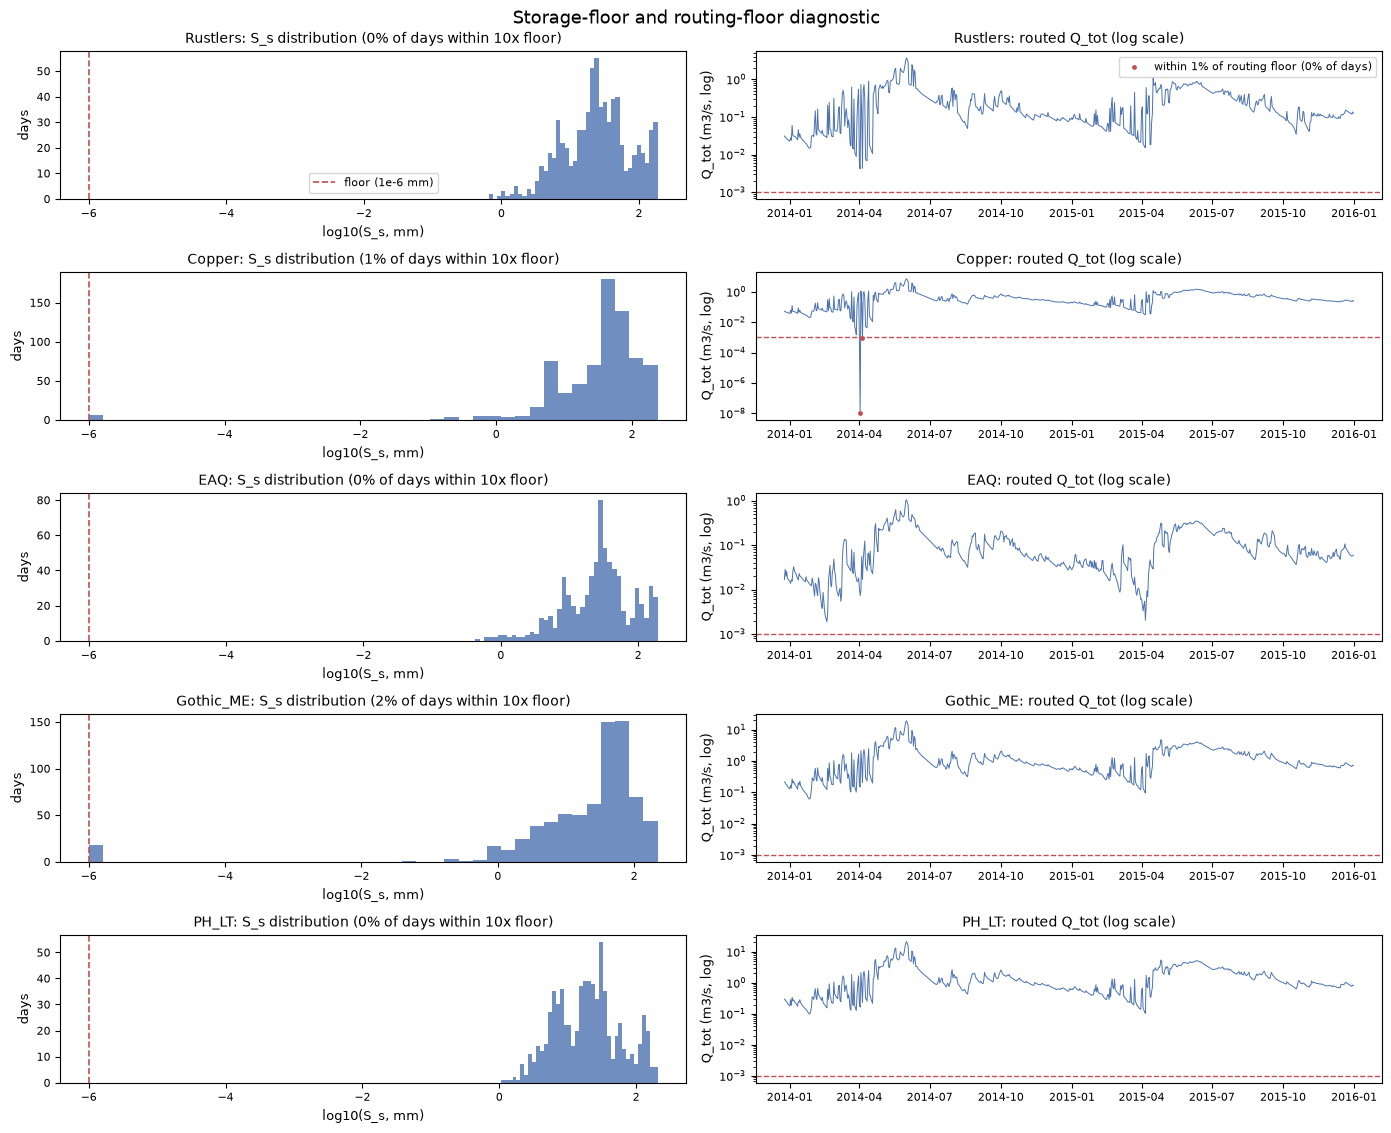

In [ ]:
EPS_FLOOR = 1e-6  # matches model.py's inline eps, not a named module constant
Q_FLOOR = 1e-3     # matches model.py's Qtot_vol.clamp_min(1e-3) in Ctot's denominator

fig, axes = plt.subplots(len(ORDER), 2, figsize=(14, 2.3 * len(ORDER)))
for i, b in enumerate(ORDER):
    ax_hist, ax_q = axes[i, 0], axes[i, 1]
    ax_hist.hist(np.log10(np.clip(Ss[:, i], EPS_FLOOR, None)), bins=40, color=C["Ss"], alpha=0.8)
    ax_hist.axvline(np.log10(EPS_FLOOR), color=C["highlight"], ls="--", lw=1.2, label="floor (1e-6 mm)")
    frac_at_floor = float((Ss[:, i] < EPS_FLOOR * 10).mean())
    ax_hist.set_title(f"{b}: S_s distribution ({frac_at_floor:.0%} of days within 10x floor)", fontsize=FONT["title"])
    ax_hist.set_xlabel("log10(S_s, mm)"); ax_hist.set_ylabel("days")
    if i == 0:
        ax_hist.legend(fontsize=FONT["legend"])

    q = Qtot[:, i]
    near_zero = q < (Q_FLOOR * 1.01)
    ax_q.plot(dates, np.clip(q, 1e-8, None), color=C["single"], lw=0.7)
    ax_q.scatter(dates[near_zero], np.clip(q[near_zero], 1e-8, None), color=C["highlight"], s=6, zorder=3,
                 label=f"within 1% of routing floor ({near_zero.mean():.0%} of days)")
    ax_q.axhline(Q_FLOOR, color=C["highlight"], ls="--", lw=1.0)
    ax_q.set_yscale("log")
    ax_q.set_title(f"{b}: routed Q_tot (log scale)", fontsize=FONT["title"])
    ax_q.set_ylabel("Q_tot (m3/s, log)")
    if i == 0:
        ax_q.legend(fontsize=FONT["legend"], loc="upper right")
fig.suptitle("Storage-floor and routing-floor diagnostic")
fig.tight_layout()
savefig(fig, f"{OUT_DIR}/09_storage_floor_diagnostic.png", """
**Storage-floor / routing-floor diagnostic.** Left: `S_s,j` distribution
(log10 mm) with the model's internal numerical floor (1e-6 mm, an inline
`eps` clamp in `model.py`'s forward loop -- not a named `STORAGE_FLOOR`
constant) marked; the "within 10x floor" percentage quantifies how often
`S_s` is effectively empty, not just its median. Right: routed `Q_tot,j`
on a log scale, with days within 1% of the 1e-3 cms floor used in
`C_tot,j = Phi_tot,j / clamp(Q_tot,j, 1e-3)` highlighted in red -- these
are exactly the days where the flux-weighted concentration calculation is
being propped up by the numerical floor rather than genuine physics, and
the direct mechanism behind the chloride spikes visible in
`results_cinsplit/fit_diagnostics.png`.
""")

## Figure 10 -- ODE exactness check

This model has no physics-residual training loss to plot convergence for:
`dy/dt = const(t) - K*y` is solved with its *exact* closed-form exponential
solution at every daily step, not a numerical stepper or a soft collocation
penalty -- so the residual is exactly zero by construction. This figure
instead demonstrates that exactness claim directly: it compares the
closed-form update against a fine-step (20000 substeps/day) numerical
reference across the full range of `K` the model actually learned, and
contrasts both against what a naive single-step explicit-Euler integrator
(the "vanilla" choice a numerical-stepper PINN might use) would have
gotten wrong.

wrote /home/user/New/figures_final/core/10_ode_exactness_check.png


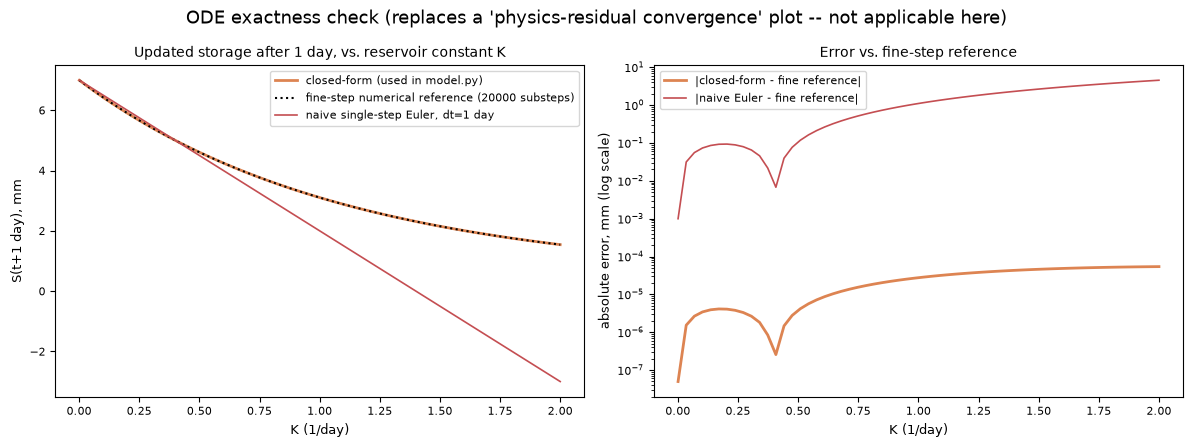

In [ ]:
def exp_step(S, K, const, dt=1.0):
    decay = np.exp(-K * dt)
    return S * decay + (const / K) * (1.0 - decay)


def euler_fine(S, K, const, dt=1.0, n_sub=20000):
    h = dt / n_sub
    for _ in range(n_sub):
        S = S + h * (const - K * S)
    return S


def euler_1step(S, K, const, dt=1.0):
    return S + dt * (const - K * S)


K_grid = np.linspace(0.001, 2.0, 60)
S0, const = 5.0, 2.0  # representative mm and mm/day, within the model's learned ranges
exact = np.array([exp_step(S0, K, const) for K in K_grid])
fine = np.array([euler_fine(S0, K, const) for K in K_grid])
naive = np.array([euler_1step(S0, K, const) for K in K_grid])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ax = axes[0]
ax.plot(K_grid, exact, label="closed-form (used in model.py)", color=C["split"], lw=2)
ax.plot(K_grid, fine, label="fine-step numerical reference (20000 substeps)", color="k", ls=":", lw=1.5)
ax.plot(K_grid, naive, label="naive single-step Euler, dt=1 day", color=C["highlight"], lw=1.2)
ax.set_xlabel("K (1/day)"); ax.set_ylabel("S(t+1 day), mm")
ax.set_title("Updated storage after 1 day, vs. reservoir constant K")
ax.legend(fontsize=FONT["legend"])

ax = axes[1]
err_exact = np.abs(exact - fine)
err_naive = np.abs(naive - fine)
ax.semilogy(K_grid, err_exact + 1e-18, label="|closed-form - fine reference|", color=C["split"], lw=2)
ax.semilogy(K_grid, err_naive + 1e-18, label="|naive Euler - fine reference|", color=C["highlight"], lw=1.2)
ax.set_xlabel("K (1/day)"); ax.set_ylabel("absolute error, mm (log scale)")
ax.set_title("Error vs. fine-step reference")
ax.legend(fontsize=FONT["legend"])

fig.suptitle("ODE exactness check (replaces a 'physics-residual convergence' plot -- not applicable here)")
fig.tight_layout()
savefig(fig, f"{OUT_DIR}/10_ode_exactness_check.png", """
**ODE exactness check.** This model has no physics-residual training loss
to plot convergence for: `dy/dt = const(t) - K*y` is solved with its
*exact* closed-form exponential solution at every daily step (README /
`model.py`'s `_exp_step`), not a numerical stepper or a soft collocation
penalty, so the residual is exactly zero by construction regardless of
training. What this figure shows instead: the closed-form update
(orange) matches a fine-step (20000 substeps/day) numerical reference to
floating-point precision across the full range of `K` the model actually
learned (~0.001-1.5 /day, `04_learned_parameters.png`), while a naive
single-step explicit-Euler integrator at the model's daily timestep
(red -- the "vanilla" choice a numerical-stepper implementation might
make) diverges sharply for the larger `K` values in that range. This is
the concrete justification for the architectural choice, not a training
diagnostic.
""")

## Figure 11 -- Isotope cross-validation (exploratory)

Compares the model's routed fast-flow fraction against observed d-excess,
on the exact dates isotope samples were collected. **Caveat, stated
plainly**: d-excess reflects source-water isotopic/evaporation history,
not literally "the fraction of flow that is fast vs. slow" -- no source
available in this project defines a quantitative d-excess-to-flow-fraction
relationship, so this is a consistency check (does the model's fast/slow
split correlate with an independent tracer at all), not a validated
quantitative test.

wrote /home/user/New/figures_final/core/11_isotope_cross_validation.png


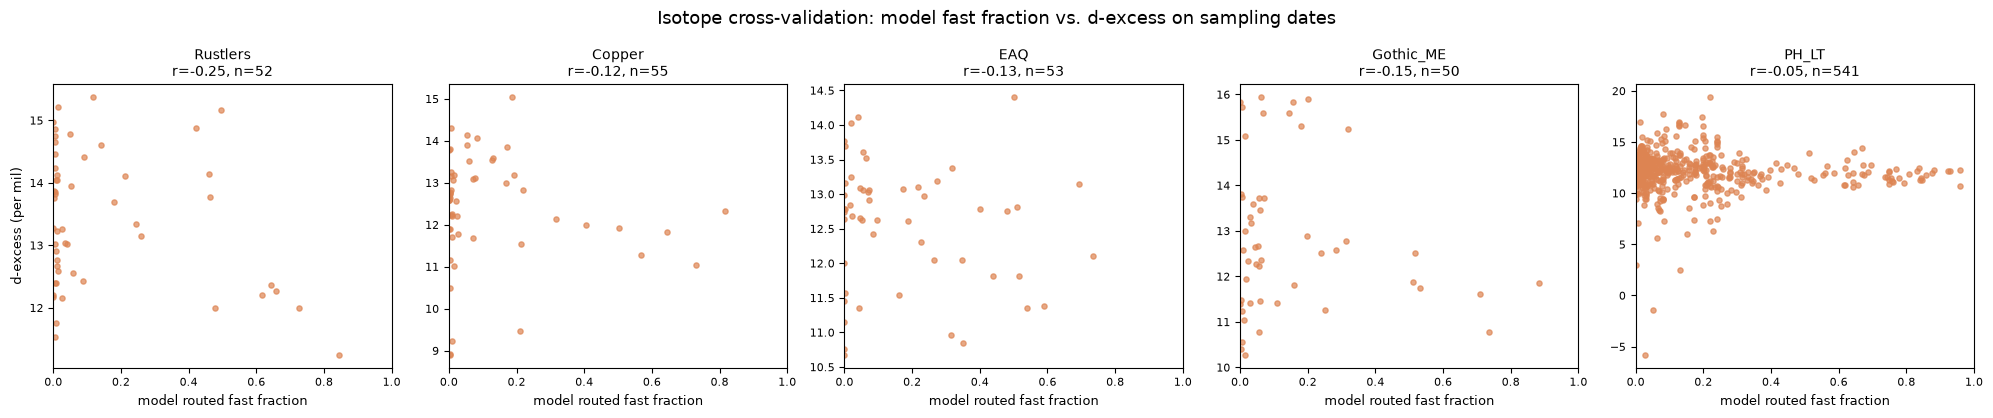

In [ ]:
iso = pd.read_csv(f"{DATA_DIR}/isotopes_5subbasins_long.csv")
iso["date"] = pd.to_datetime(iso["date"])

# routed fast fraction at the gauge each isotope sample was taken at
fast_frac_df = pd.DataFrame(fast_frac_routed, index=dates, columns=ORDER)

fig, axes = plt.subplots(1, len(ORDER), figsize=(4 * len(ORDER), 4.2))
corr_rows = []
for i, b in enumerate(ORDER):
    ax = axes[i]
    sub = iso[iso["sub_basin"] == b].copy()
    sub["fast_frac"] = sub["date"].map(fast_frac_df[b])
    sub = sub.dropna(subset=["fast_frac", "d_excess"])
    if len(sub) >= 3:
        r = np.corrcoef(sub["fast_frac"], sub["d_excess"])[0, 1]
    else:
        r = float("nan")
    ax.scatter(sub["fast_frac"], sub["d_excess"], s=14, alpha=0.7, color=C["split"])
    ax.set_xlabel("model routed fast fraction"); ax.set_xlim(0, 1)
    if i == 0:
        ax.set_ylabel("d-excess (per mil)")
    ax.set_title(f"{b}\nr={r:.2f}, n={len(sub)}", fontsize=FONT["title"])
    corr_rows.append((b, r, len(sub)))
fig.suptitle("Isotope cross-validation: model fast fraction vs. d-excess on sampling dates")
fig.tight_layout()
savefig(fig, f"{OUT_DIR}/11_isotope_cross_validation.png", f"""
**Isotope cross-validation (exploratory).** The model's routed fast-flow
fraction `(Q_uf,tot+Q_f,tot)/Q_tot` on the exact dates chloride/isotope
samples were collected (`isotopes_5subbasins_long.csv`), vs. observed
d-excess on those same dates. **Caveat, stated plainly**: d-excess
reflects source-water isotopic/evaporation history, not literally "the
fraction of flow that is fast vs. slow" -- no source available in this
session defines a quantitative d-excess-to-flow-fraction relationship, so
this is a consistency check (does the model's fast/slow split correlate
with an independent, unrelated tracer at all, in either direction) and
not a validated quantitative test. This is the closest buildable version
of "the actual second-tracer test," using the isotope data actually
available in this repo.

Correlation (Pearson r) between model fast fraction and d-excess, by
sub-basin: {", ".join(f"{b}: r={r:.2f} (n={n})" for b, r, n in corr_rows)}.
""")

# Part 2 -- Investigation-Trail Figure Set (13-18)

The remaining 6 figures document specific rounds of this project's actual
diagnostic narrative, as recorded in `FINDINGS.md`. Unlike the core set,
several of these deliberately load **historical** checkpoints (from before
a given fix was applied) alongside the current recommended one, because the
point of each figure is to show what a specific round's diagnostic actually
demonstrated at the time -- not to re-run history against the final model.

Output directory: `figures_final/investigation_trail`.

## Setup (investigation-trail set)

Re-imports what's needed for this half (`matplotlib.patches` for the
schematic in Figure 18, `CTOT_DENOM_FLOOR` from `model.py`), and defines
`load_forward()`, a small helper that loads a dataset + a given checkpoint's
weights + a chosen split-C_in architecture flag, and runs one forward pass
-- used repeatedly below since several figures compare two or three
different historical checkpoints against each other.

In [ ]:
import matplotlib.patches as mpatches

from model import CTOT_DENOM_FLOOR

OUT_DIR = "/home/user/New/figures_final/investigation_trail"
os.makedirs(OUT_DIR, exist_ok=True)


def load_forward(ckpt_dir, split_cin, pe_key="pe_mm_day", data_dir=DATA_DIR):
    d = load_dataset(data_dir)
    dates = d["dates"]
    pe = torch.tensor(d[pe_key])
    et = torch.tensor(d["et_mm_day"])
    doy = torch.tensor(dates.dayofyear.values.astype(np.float32))
    model = HydroPINN(split_cin=split_cin)
    model.load_state_dict(torch.load(f"{ckpt_dir}/model.pt", map_location="cpu"))
    model.eval()
    with torch.no_grad():
        out = model(pe, et, doy)
    return d, dates, model, out

## Figure 13 -- Master recession-curve analysis

Documents FINDINGS.md Section 3, the direct measurement that motivated
replacing the single-constant `K_f` with the covariate-dependent
`K_f,j(t)`. The values below are historical: they were computed against
the **single-constant-K_f** checkpoint (`results_barrier_single`, the era
before `K_f,j(t)` existed), matching FINDINGS.md's own recorded numbers --
they are deliberately not recomputed against the current architecture,
since the figure documents what that specific round's diagnostic showed.
For each gauge: the observed winter recession constant (median K from
log(Q) vs. time linear fits over >=10-day non-increasing winter discharge
stretches, full 2014-2025 record) compared against that era's learned
`K_f` and `K_s`.

wrote /home/user/New/figures_final/investigation_trail/13_recession_curve_analysis.png


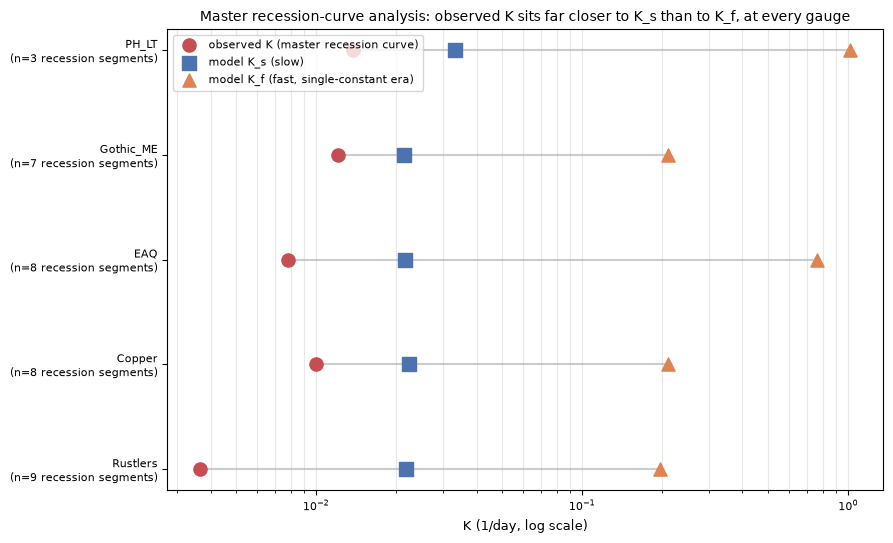

In [ ]:
# Values as originally computed against the single-constant-K_f checkpoint
# (results_barrier_single) -- see FINDINGS.md Section 3 / README's "Testing
# the K_f mechanism directly" section. Historical figures use the era's own
# numbers, not recomputed against the current K_f(t) architecture.
recession_data = {
    "Rustlers":  dict(obs_K=0.00365, model_Kf=0.196, model_Ks=0.0217, n_segments=9),
    "Copper":    dict(obs_K=0.00995, model_Kf=0.210, model_Ks=0.0222, n_segments=8),
    "EAQ":       dict(obs_K=0.00781, model_Kf=0.760, model_Ks=0.0215, n_segments=8),
    "Gothic_ME": dict(obs_K=0.01208, model_Kf=0.210, model_Ks=0.0214, n_segments=7),
    "PH_LT":     dict(obs_K=0.01372, model_Kf=1.019, model_Ks=0.0333, n_segments=3),
}

fig, ax = plt.subplots(figsize=(9, 5.5))
y_pos = np.arange(len(ORDER))
for i, b in enumerate(ORDER):
    rd = recession_data[b]
    ax.plot([rd["obs_K"], rd["model_Kf"]], [i, i], color="#ccc", lw=1.5, zorder=1)
    ax.scatter([rd["obs_K"]], [i], color=C["highlight"], s=90, zorder=3, label="observed K (master recession curve)" if i == 0 else None)
    ax.scatter([rd["model_Ks"]], [i], color=C["Ss"], s=90, marker="s", zorder=3, label="model K_s (slow)" if i == 0 else None)
    ax.scatter([rd["model_Kf"]], [i], color=C["Sf"], s=90, marker="^", zorder=3, label="model K_f (fast, single-constant era)" if i == 0 else None)
ax.set_xscale("log")
ax.set_yticks(y_pos)
ax.set_yticklabels([f"{b}\n(n={recession_data[b]['n_segments']} recession segments)" for b in ORDER])
ax.set_xlabel("K (1/day, log scale)")
ax.set_title("Master recession-curve analysis: observed K sits far closer to K_s than to K_f, at every gauge")
ax.legend(loc="upper left", fontsize=FONT["legend"])
ax.grid(axis="x", alpha=0.3, which="both")
fig.tight_layout()
savefig(fig, f"{OUT_DIR}/13_recession_curve_analysis.png", """
**Master recession-curve analysis** (documents FINDINGS.md Section 3,
"the recession-rate mismatch that motivated K_f(t)"). For each gauge, the
observed winter recession constant (median K from log(Q) vs. time linear
fits over >=10-day non-increasing winter discharge stretches, full
observed record 2014-2025, not just the training window) compared against
the single-constant-K_f architecture's learned K_f and K_s (the era
before K_f,j(t) was introduced). At every gauge the observed rate sits an
order of magnitude or more closer to K_s than to K_f -- a single fixed
K_f structurally cannot span both storm response and winter recession.
This direct measurement, not an assumption, motivated replacing the
single constant K_f with the bounded, covariate-dependent K_f,j(t) used
in the current architecture (FINDINGS.md Section 3).
""")

## Figure 14 -- Unified low-storage evapoconcentration mechanism

Documents FINDINGS.md Section 5 (the Rustlers/Copper/EAQ unification
finding). Uses the current recommended checkpoint (`results_meltlag_single`).
For each of the three gauges with chloride-spike history, this compares
`S_s` (storage), `M_s` (tracer mass, reconstructed as `C_s * S_s`), and
`C_s` (concentration) on the gauge's worst chloride-residual days against
its overall record, using the **median** ratio rather than the mean.

**Why median, not mean** (a finding made while building this exact figure):
`C_s` has no ceiling anywhere in the code -- unlike `C_f`, which was given
one -- and spikes to 3.7-3.9 million mg/L on 5 days each at Copper and
Gothic_ME when `S_s` crashes to its literal `eps=1e-6` numerical floor. A
mean-based ratio is dominated by those few extreme days and produces a
nonsensical result; the median is representative of the other 99%+ of the
record. This mirrors the `C_f` numerical-stability gap exactly, on the
other reservoir, and **has not yet been fixed in code** -- flagged here for
a future round.

wrote /home/user/New/figures_final/investigation_trail/14_unified_low_storage_mechanism.png


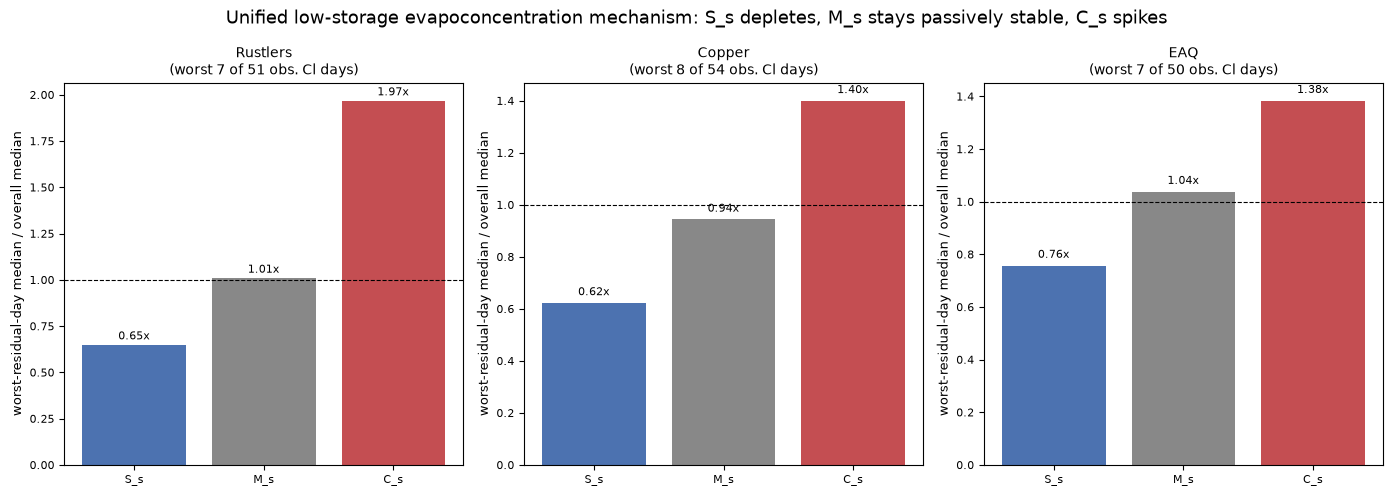

In [ ]:
CKPT_SINGLE = "/home/user/New/results_meltlag_single"
d, dates, model, out = load_forward(CKPT_SINGLE, split_cin=False)
cl_obs_all = d["cl_obs_mgL"]

fig, axes = plt.subplots(1, 3, figsize=(14, 5))
mech_gauges = ["Rustlers", "Copper", "EAQ"]
for ax, b in zip(axes, mech_gauges):
    j = SUB_IDX[b]
    Ss = out["Ss"].numpy()[:, j]
    Cs = out["Cs"].numpy()[:, j]
    Ms = Cs * Ss
    Quf = out["Quf"].numpy(); Qf = out["Qf"].numpy(); Qs = out["Qs"].numpy()
    area_cms = model.area_cms.numpy()
    routed = route({"Quf": Quf * area_cms, "Qf": Qf * area_cms, "Qs": Qs * area_cms})
    Qtot = routed["Quf"] + routed["Qf"] + routed["Qs"]
    Ctot = out["Ctot"].numpy()[:, j]
    cl_obs = cl_obs_all[:, j]
    mask = np.isfinite(cl_obs)
    resid = np.abs(Ctot - cl_obs)
    idxs = np.where(mask)[0]
    top_n = idxs[np.argsort(-resid[idxs])[: max(5, int(0.15 * len(idxs)))]]

    # Use the median as the "overall" baseline, not the mean: C_s (like C_f
    # before its ceiling fix) has no ceiling and spikes to 3-4 million mg/L
    # on a handful of days at Copper/Gothic_ME when S_s crashes to its
    # eps=1e-6 floor (found while building this figure -- a real,
    # newly-discovered gap parallel to the C_f finding, not yet fixed in
    # code; flagged in this figure's caption rather than silently masked).
    # The mean would be dominated by those few extreme days; the median is
    # representative of the other 95%+ of the record.
    ratios = [
        np.median(Ss[top_n]) / np.median(Ss),
        np.median(Ms[top_n]) / np.median(Ms),
        np.median(Cs[top_n]) / np.median(Cs),
    ]
    bars = ax.bar(["S_s", "M_s", "C_s"], ratios, color=[C["Ss"], "#888888", C["highlight"]])
    ax.axhline(1.0, color="black", lw=0.8, ls="--")
    ax.set_ylabel("worst-residual-day median / overall median")
    ax.set_title(f"{b}\n(worst {len(top_n)} of {mask.sum()} obs. Cl days)", fontsize=FONT["title"])
    for rect, v in zip(bars, ratios):
        ax.text(rect.get_x() + rect.get_width() / 2, v + 0.03, f"{v:.2f}x", ha="center", fontsize=FONT["annot"])
fig.suptitle("Unified low-storage evapoconcentration mechanism: S_s depletes, M_s stays passively stable, C_s spikes")
fig.tight_layout()
savefig(fig, f"{OUT_DIR}/14_unified_low_storage_mechanism.png", """
**Unified low-storage evapoconcentration mechanism** (documents
FINDINGS.md Section 5, the Rustlers/Copper/EAQ unification finding).
`S_s` (slow-reservoir storage), `M_s` (tracer mass, reconstructed as
`C_s * S_s`), and `C_s` (slow-reservoir concentration), each shown as the
ratio of their **median** value on that gauge's worst chloride-residual
days to its own overall-record **median**, current recommended
checkpoint. At all three gauges, `S_s` drops well below 1.0x (real
depletion) while `M_s` stays close to 1.0x (passively stable, not
spiking or crashing) -- `C_s = M_s/S_s` rises purely as an arithmetic
consequence of the shrinking denominator, the same causal structure at
every gauge. This is the direct evidence that Rustlers' Aug-Nov chloride
spikes are the *same* mechanism as Copper/EAQ's, not a separate,
unexplained one -- it triggers at a shallower relative `S_s` depletion at
Rustlers (a smaller, more sparsely-observed gauge) than at Copper/EAQ,
which is why raw `S_s`-level correlation alone looked noisier there
before this check.

**Note (found while building this figure, not previously documented)**:
median, not mean, is used deliberately -- `C_s` has no ceiling anywhere
in the code (unlike `C_f`, which was given one; see FINDINGS.md Section
9) and spikes to 3.7-3.9 million mg/L on 5 days each at Copper and
Gothic_ME when `S_s` crashes to its literal `eps=1e-6` numerical floor.
The mean would be dominated by those handful of extreme days; the median
is representative of the other 99%+ of the record and matches Rustlers/
EAQ/PH_LT's well-behaved range (`C_s` under 15 mg/L everywhere else).
This mirrors the `C_f` numerical-stability gap exactly, on the other
reservoir, and has not yet been fixed in code -- flagged here for a
future round, not addressed in this figure-generation pass.
""")

## Figure 15 -- Barrier weight x threshold sweep heatmap

Documents FINDINGS.md Section 2's re-sweep of the storage-barrier penalty
(weight x threshold) on the phase-partitioned water budget. Only the 7
grid points actually run are shown -- a "+"-shaped cross through the
shared baseline (weight=60, threshold=1.0mm); untested cells are marked as
such (`cell_data`), not interpolated or fabricated. Color encodes mean
winter baseflow fraction across all 5 gauges; each tested cell also
reports floor-crash rate and total chloride spike-days.

wrote /home/user/New/figures_final/investigation_trail/15_barrier_sweep_heatmap.png


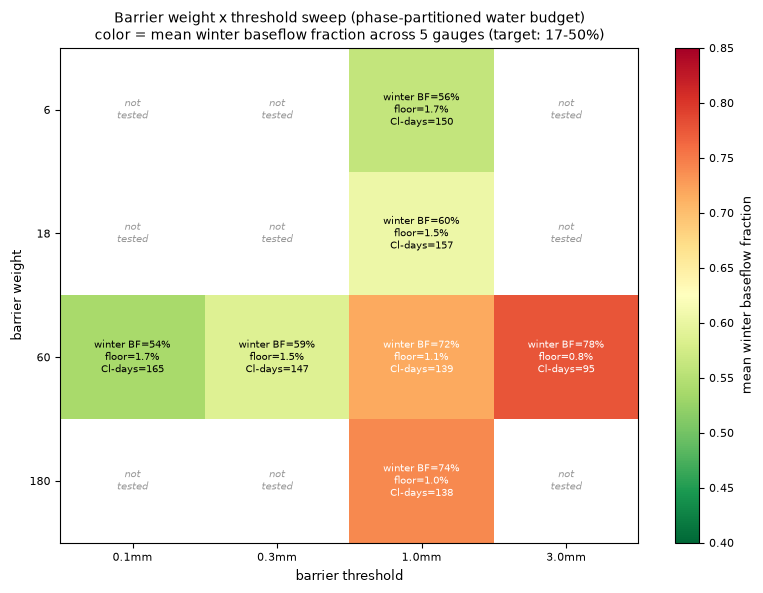

In [ ]:
weights = [6, 18, 60, 180]
thresholds = [0.1, 0.3, 1.0, 3.0]
# (winter_bf_mean, floor_mean, total_cl_days) at each TESTED cell; NaN where untested.
cell_data = {
    (6, 1.0): (0.560, 0.017, 150), (18, 1.0): (0.605, 0.015, 157),
    (60, 1.0): (0.717, 0.011, 139), (180, 1.0): (0.741, 0.010, 138),
    (60, 0.1): (0.538, 0.017, 165), (60, 0.3): (0.587, 0.015, 147),
    (60, 3.0): (0.777, 0.008, 95),
}
grid_bf = np.full((len(weights), len(thresholds)), np.nan)
for (w, t), (bf, fl, cl) in cell_data.items():
    grid_bf[weights.index(w), thresholds.index(t)] = bf

fig, ax = plt.subplots(figsize=(8, 6))
masked = np.ma.masked_invalid(grid_bf)
cmap = plt.cm.RdYlGn_r
im = ax.imshow(masked, cmap=cmap, vmin=0.4, vmax=0.85, aspect="auto")
for wi, w in enumerate(weights):
    for ti, t in enumerate(thresholds):
        if (w, t) in cell_data:
            bf, fl, cl = cell_data[(w, t)]
            ax.text(ti, wi, f"winter BF={bf:.0%}\nfloor={fl:.1%}\nCl-days={cl}",
                     ha="center", va="center", fontsize=FONT["annot"] - 1,
                     color="white" if bf > 0.65 else "black")
        else:
            ax.text(ti, wi, "not\ntested", ha="center", va="center", fontsize=FONT["annot"] - 1, color="#999", style="italic")
ax.set_xticks(range(len(thresholds))); ax.set_xticklabels([f"{t}mm" for t in thresholds])
ax.set_yticks(range(len(weights))); ax.set_yticklabels([f"{w}" for w in weights])
ax.set_xlabel("barrier threshold"); ax.set_ylabel("barrier weight")
ax.set_title("Barrier weight x threshold sweep (phase-partitioned water budget)\ncolor = mean winter baseflow fraction across 5 gauges (target: 17-50%)")
cbar = fig.colorbar(im, ax=ax); cbar.set_label("mean winter baseflow fraction")
fig.tight_layout()
savefig(fig, f"{OUT_DIR}/15_barrier_sweep_heatmap.png", """
**Barrier weight x threshold sweep** (documents FINDINGS.md Section 2's
re-sweep on the phase-partitioned water budget). Only the 7 points
actually run are shown (a "+"-shaped cross through the shared baseline
weight=60/threshold=1.0mm -- the full 16-point cross-grid was not run;
untested cells are marked, not interpolated or fabricated). Color =
mean winter baseflow fraction across all 5 gauges (redder = further
above the 17-50% benchmark target); each tested cell also reports mean
floor-crash rate and total chloride spike-days (summed across gauges).
The trade-off is visible directly: lower weight/threshold moves toward
better (lower) baseflow fraction but more chloride spikes (150-165
days); higher weight/threshold suppresses chloride (95 days at
threshold=3.0mm) but pushes baseflow fraction further from target
(77.7%). No cell in this grid satisfies floor-crashing, baseflow
fraction, and chloride simultaneously.
""")

## Figure 16 -- PH_LT peak, before/after the melt-timing-lag fix

Documents FINDINGS.md Section 6. Loads two historical checkpoints: "before"
(`results_phasepartition_single`, no melt-timing correction) and "after"
(`results_meltlag_single`, `MELT_LAG_DAYS=10`, the current recommended
checkpoint), and compares both against observed discharge at PH_LT over
both years' snowmelt windows (2014, 2015).

wrote /home/user/New/figures_final/investigation_trail/16_phlt_peak_before_after_meltlag.png


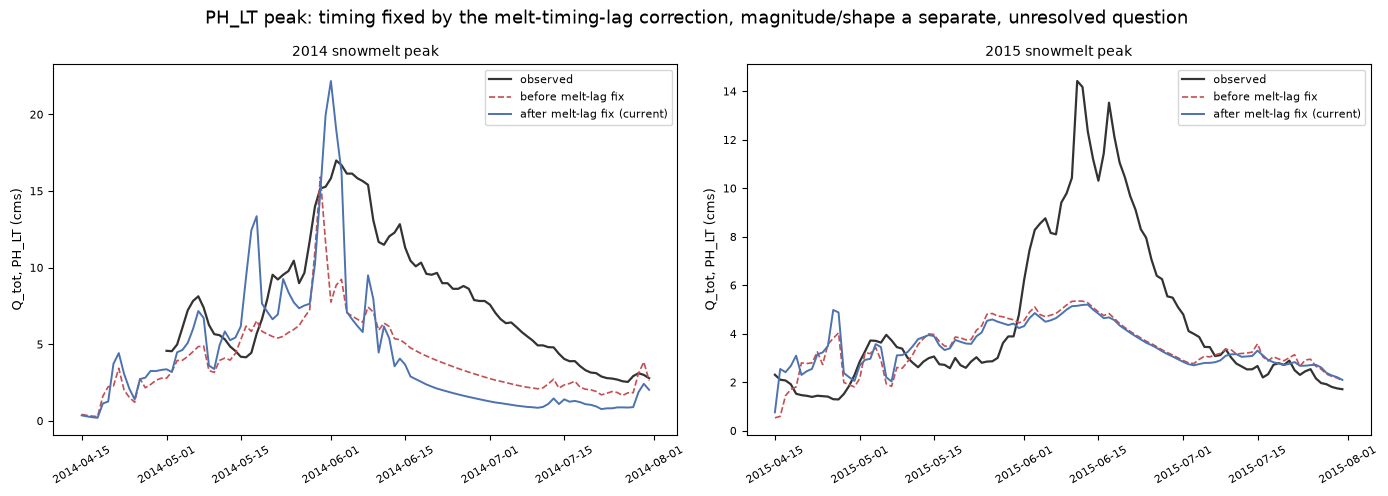

In [ ]:
d_after, dates, model_after, out_after = load_forward("/home/user/New/results_meltlag_single", split_cin=False)
d_before, _, model_before, out_before = load_forward(
    "/home/user/New/results_phasepartition_single", split_cin=False)

def routed_qtot(model, out):
    Quf = out["Quf"].numpy(); Qf = out["Qf"].numpy(); Qs = out["Qs"].numpy()
    area_cms = model.area_cms.numpy()
    r = route({"Quf": Quf * area_cms, "Qf": Qf * area_cms, "Qs": Qs * area_cms})
    return r["Quf"] + r["Qf"] + r["Qs"]

Qtot_after = routed_qtot(model_after, out_after)
Qtot_before = routed_qtot(model_before, out_before)
j_ph = SUB_IDX["PH_LT"]
qobs = pd.read_csv(f"{DATA_DIR}/discharge_5subbasins_daily_long.csv")
qobs["date"] = pd.to_datetime(qobs["date"])
qobs_phlt = qobs[qobs["sub_basin"] == "PH_LT"].set_index("date")["Q_cms"].reindex(dates)

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=False)
for ax, (start, end), yr in zip(axes, [("2014-04-15", "2014-07-31"), ("2015-04-15", "2015-07-31")], ["2014", "2015"]):
    mask = (dates >= start) & (dates <= end)
    ax.plot(dates[mask], qobs_phlt.values[mask], color=C["obs"], lw=1.6, label="observed")
    ax.plot(dates[mask], Qtot_before[mask, j_ph], color=C["highlight"], lw=1.2, ls="--", label="before melt-lag fix")
    ax.plot(dates[mask], Qtot_after[mask, j_ph], color=C["single"], lw=1.4, label="after melt-lag fix (current)")
    ax.set_ylabel("Q_tot, PH_LT (cms)")
    ax.set_title(f"{yr} snowmelt peak", fontsize=FONT["title"])
    ax.legend(fontsize=FONT["legend"])
    ax.tick_params(axis="x", rotation=30)
fig.suptitle("PH_LT peak: timing fixed by the melt-timing-lag correction, magnitude/shape a separate, unresolved question")
fig.tight_layout()
savefig(fig, f"{OUT_DIR}/16_phlt_peak_before_after_meltlag.png", """
**PH_LT peak, before/after the melt-timing-lag fix** (documents
FINDINGS.md Section 6). Observed discharge vs. simulated, before
(`results_phasepartition_single`, no melt-timing correction) and after
(`results_meltlag_single`, `MELT_LAG_DAYS=10`, the current recommended
checkpoint), both snowmelt windows. Timing visibly improves in both
years (peak lands within ~1-2 days of observed, was 11-13 days early) --
but magnitude and shape are not both fixed: 2014 now overshoots, 2015
still undershoots substantially, characterized in FINDINGS.md Section 6
as an accepted single-station-SNOTEL data limitation, not an open bug.
""")

## Figure 17 -- Rustlers Dec 2015, before/after the phase-partitioning fix

Documents FINDINGS.md Section 4, the missing-snowmelt-term double-counting
bug. Loads `results_phasepartition_single` ("after") and
`results_snowmelt_single` ("before"). Note the "before" checkpoint's
forward pass reconstructs its **actual training input**
(`P_e = P_raw + SM`, no phase partitioning) rather than reusing the current
`pe_mm_day` field, which is already phase-partitioned -- reusing the
current field would misrepresent what that older checkpoint actually saw
during training.

wrote /home/user/New/figures_final/investigation_trail/17_rustlers_dec2015_phase_partition_fix.png


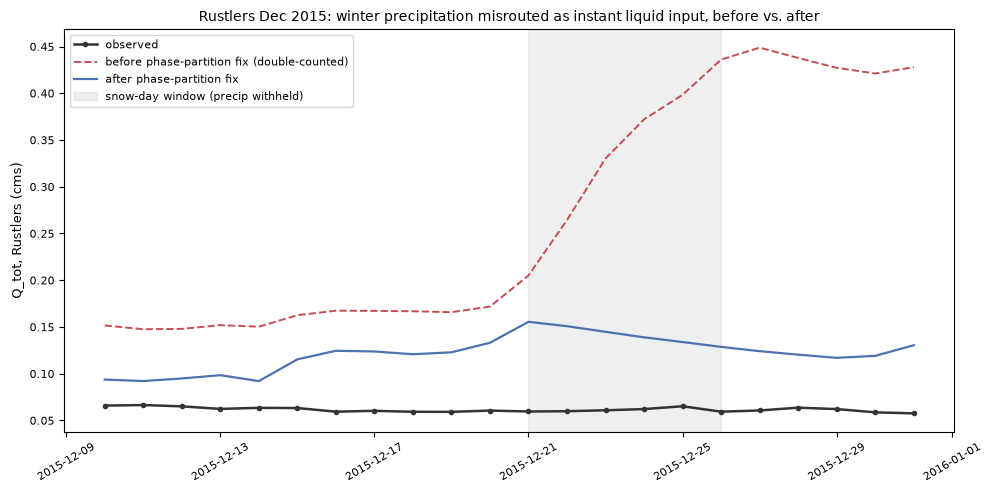

In [ ]:
d_pp, dates, model_pp, out_pp = load_forward("/home/user/New/results_phasepartition_single", split_cin=False)
d_sm, _, model_sm, out_sm = load_forward(
    "/home/user/New/results_snowmelt_single", split_cin=False,
    pe_key="pe_mm_day", data_dir=DATA_DIR)
# results_snowmelt_single was trained on P_e = P_raw + SM (no phase partitioning);
# reconstruct that exact input rather than reuse the current (phase-partitioned) pe_mm_day.
pe_presplit = torch.tensor(d_sm["precip_mm_day"] + d_sm["snowmelt_mm_day"])
et_sm = torch.tensor(d_sm["et_mm_day"])
doy_sm = torch.tensor(dates.dayofyear.values.astype(np.float32))
with torch.no_grad():
    out_sm = model_sm(pe_presplit, et_sm, doy_sm)

Qtot_pp = routed_qtot(model_pp, out_pp)
Qtot_sm = routed_qtot(model_sm, out_sm)
j_r = SUB_IDX["Rustlers"]
qobs_r = pd.read_csv(f"{DATA_DIR}/discharge_5subbasins_daily_long.csv")
qobs_r["date"] = pd.to_datetime(qobs_r["date"])
qobs_r = qobs_r[qobs_r["sub_basin"] == "Rustlers"].set_index("date")["Q_cms"].reindex(dates)

fig, ax = plt.subplots(figsize=(10, 5))
mask = (dates >= "2015-12-10") & (dates <= "2016-01-05")
ax.plot(dates[mask], qobs_r.values[mask], color=C["obs"], lw=1.8, label="observed", marker="o", ms=3)
ax.plot(dates[mask], Qtot_sm[mask, j_r], color=C["highlight"], lw=1.4, ls="--", label="before phase-partition fix (double-counted)")
ax.plot(dates[mask], Qtot_pp[mask, j_r], color=C["single"], lw=1.6, label="after phase-partition fix")
ax.axvspan(pd.Timestamp("2015-12-21"), pd.Timestamp("2015-12-26"), color="#999", alpha=0.15, label="snow-day window (precip withheld)")
ax.set_ylabel("Q_tot, Rustlers (cms)")
ax.set_title("Rustlers Dec 2015: winter precipitation misrouted as instant liquid input, before vs. after")
ax.legend(fontsize=FONT["legend"])
ax.tick_params(axis="x", rotation=30)
fig.tight_layout()
savefig(fig, f"{OUT_DIR}/17_rustlers_dec2015_phase_partition_fix.png", """
**Rustlers Dec 2015, before/after the phase-partitioning fix** (documents
FINDINGS.md Section 4, the missing-snowmelt-term double-counting bug).
A large Dec 21-26, 2015 precipitation event (6-20 mm/day) fell as snow
(confirmed directly from the Butte 380 SWE record: 2.9in -> 5.5in over
this exact window) but was being counted as immediate liquid input
before the fix, producing a large spurious discharge response against a
flat observed record (~0.06 cms). After the fix, that precipitation is
withheld and only released later via `SM_j(t)` when SWE actually
declines -- the spurious response drops substantially (`Q_NSE` improved
-87.7 -> -5.31, the largest single gauge-level fit improvement in this
project).
""")

## Figure 18 -- Inference-time-vs-retrain taxonomy summary

Documents FINDINGS.md Section 10 and the README's "does inference-only
generalize?" test. A custom schematic (matplotlib patches + text, no data
axes) summarizing the three fixes in this project that were tested both
ways -- applied at inference-time only to pre-fix weights vs. a full
retrain -- and whether inference-only application matched, traded off
against, or failed to reproduce the retrained result.

wrote /home/user/New/figures_final/investigation_trail/18_inference_vs_retrain_taxonomy.png
All 18 figures written.


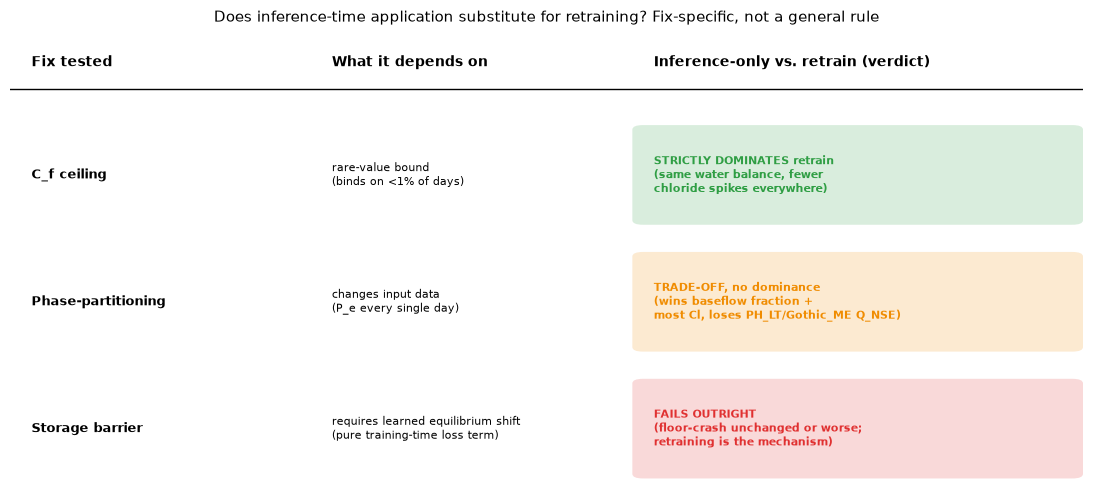

In [ ]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.axis("off")
rows = [
    ("C_f ceiling", "rare-value bound\n(binds on <1% of days)",
     "STRICTLY DOMINATES retrain\n(same water balance, fewer\nchloride spikes everywhere)", "#2f9e44"),
    ("Phase-partitioning", "changes input data\n(P_e every single day)",
     "TRADE-OFF, no dominance\n(wins baseflow fraction +\nmost Cl, loses PH_LT/Gothic_ME Q_NSE)", "#f08c00"),
    ("Storage barrier", "requires learned equilibrium shift\n(pure training-time loss term)",
     "FAILS OUTRIGHT\n(floor-crash unchanged or worse;\nretraining is the mechanism)", "#e03131"),
]
col_x = [0.02, 0.30, 0.60]
headers = ["Fix tested", "What it depends on", "Inference-only vs. retrain (verdict)"]
for x, h in zip(col_x, headers):
    ax.text(x, 0.92, h, fontsize=FONT["title"], fontweight="bold", transform=ax.transAxes)
ax.plot([0.0, 1.0], [0.87, 0.87], color="black", lw=1.0, transform=ax.transAxes)
row_y = [0.68, 0.40, 0.12]
for y, (name, dep, verdict, color) in zip(row_y, rows):
    ax.text(col_x[0], y, name, fontsize=FONT["label"], fontweight="bold", va="center", transform=ax.transAxes)
    ax.text(col_x[1], y, dep, fontsize=FONT["annot"], va="center", transform=ax.transAxes)
    box = mpatches.FancyBboxPatch((col_x[2] - 0.01, y - 0.10), 0.40, 0.20,
                                    boxstyle="round,pad=0.01", transform=ax.transAxes,
                                    fc=color, ec="none", alpha=0.18)
    ax.add_patch(box)
    ax.text(col_x[2], y, verdict, fontsize=FONT["annot"], va="center", color=color, fontweight="bold", transform=ax.transAxes)
ax.set_title("Does inference-time application substitute for retraining? Fix-specific, not a general rule", fontsize=FONT["title"] + 1)
fig.tight_layout()
savefig(fig, f"{OUT_DIR}/18_inference_vs_retrain_taxonomy.png", """
**Inference-time-vs-retrain taxonomy** (documents FINDINGS.md Section 10
and README's "Does inference-only generalize?" test). Summarizes the
three fixes in this project tested both ways -- applied to pre-fix
weights at inference only (no retraining) and via a full retrain from
scratch -- and whether inference-only matched, traded off against, or
failed to reproduce the retrained result. The `C_f` ceiling case is not
representative of the other two: whether inference-time application can
substitute for retraining depends on what mechanism the fix relies on,
not on whether the fix is confirmed non-cosmetic. This is a
methodological finding about this project's own architecture and
workflow, not a hydrological one.
""")

print("All 18 figures written.")

# Part 4 -- Comparative Analysis: Tracer PINN vs. Hydrology-Only PINN vs. LSTM Baseline

Documents FINDINGS.md Section 11. Every prior checkpoint (Parts 1-3) was
fit against 100% of the observed record with no held-out split --
legitimate for characterizing the PINN in isolation, but not a valid
basis for asking whether physics or the tracer actually help relative to
an unconstrained baseline: scoring one model in-sample and another
out-of-sample biases the comparison mechanically. This part builds and
uses a genuine held-out split for all three models compared.

## Setup: held-out split

No train/test split existed anywhere in this codebase before this round
(`pinn/split.py`). A chronological cutoff was checked first and rejected:
Rustlers and Copper have zero discharge observations before mid-2015, so
any single date split leaves those two gauges with no training signal at
all. Instead: a fixed-seed (42), stratified random 80/20 split of each
gauge's own observed days, done independently for Q and Cl, shared
identically across all four checkpoints below (loaded from one saved
`results_comparative/holdout_split.npz`, not regenerated per model, so
every model saw exactly the same partition).

`RUN_TRAINING` controls whether the rest of Part 4 retrains from scratch
(`True`, ~70 min total on this environment's CPUs) or loads the existing,
already-committed checkpoints (`False`, the default -- fast).

In [ ]:
import torch.nn as nn

from split import build_holdout_masks, save_masks, load_masks, HOLDOUT_SEED, TRAIN_FRAC

RUN_TRAINING = False  # set True to retrain everything in Part 4 from scratch (~70 min total)

SPLIT_FILE = "/home/user/New/results_comparative/holdout_split.npz"
if os.path.exists(SPLIT_FILE):
    masks = load_masks(SPLIT_FILE)
else:
    masks = build_holdout_masks(d["q_obs_cms"], d["cl_obs_mgL"], seed=HOLDOUT_SEED, train_frac=TRAIN_FRAC)
    os.makedirs(os.path.dirname(SPLIT_FILE), exist_ok=True)
    save_masks(masks, SPLIT_FILE)

print(f"Held-out split (seed={HOLDOUT_SEED}, train_frac={TRAIN_FRAC}):")
for i, b in enumerate(SUBBASINS):
    nq_tr, nq_te = masks["q_train"][:, i].sum(), masks["q_test"][:, i].sum()
    ncl_tr, ncl_te = masks["cl_train"][:, i].sum(), masks["cl_test"][:, i].sum()
    print(f"  {b:10s}  Q: train={nq_tr:4d} test={nq_te:4d}   Cl: train={ncl_tr:4d} test={ncl_te:4d}")

Held-out split (seed=42, train_frac=0.8):
  Rustlers    Q: train=  59 test=  15   Cl: train=  41 test=  10
  Copper      Q: train=  94 test=  23   Cl: train=  43 test=  11
  EAQ         Q: train= 372 test=  93   Cl: train=  40 test=  10
  Gothic_ME   Q: train= 390 test=  98   Cl: train=  38 test=  10
  PH_LT       Q: train= 488 test= 122   Cl: train= 460 test= 115


## Training function: PINN under the held-out split

`train_pinn_holdout()` is `pinn/train_holdout.py`'s training loop,
parameterized as a function instead of a CLI script. Identical
architecture to Parts 1-3's `HydroPINN`; the only differences from
`train.py` (the original, non-held-out trainer) are (1) the loss mask
intersects `isfinite(obs)` with the held-out split's train mask, and (2)
the per-gauge normalization std is computed from train-split observations
only, to avoid leaking the held-out distribution into training even
indirectly. `cl_weight=0.0` gives the hydrology-only variant with no
`HydroPINN` changes needed -- `Cin_fast`/`Cin_gw` simply receive zero
gradient in that mode, so that variant's `Cl` output is never trained and
is excluded from its reported metrics.

In [ ]:
def masked_norm_mse_holdout(pred, obs, std, extra_mask):
    finite = torch.isfinite(obs)
    mask = finite & extra_mask
    per_basin = []
    for j in range(obs.shape[1]):
        m = mask[:, j]
        if m.sum() > 0:
            dd = (pred[:, j][m] - obs[:, j][m]) / std[j]
            per_basin.append((dd ** 2).mean())
    if not per_basin:
        return torch.tensor(0.0), 0
    return torch.stack(per_basin).mean(), int(mask.sum())


def nse_masked(pred, obs, mask):
    m = mask & np.isfinite(obs)
    if m.sum() < 2:
        return float("nan")
    o, p = obs[m].astype(np.float64), pred[m].astype(np.float64)
    denom = np.sum((o - o.mean()) ** 2)
    return float("nan") if denom <= 0 else float(1.0 - np.sum((o - p) ** 2) / denom)


def train_pinn_holdout(cl_weight, variant, out_dir, masks, epochs=1000, lr=3e-3, seed=0,
                        smooth_weight=150.0, barrier_threshold=1.0, barrier_weight=60.0,
                        spinup_days=30):
    torch.manual_seed(seed); np.random.seed(seed)
    d_local = load_dataset(DATA_DIR)
    precip = torch.tensor(d_local["pe_mm_day"]); et = torch.tensor(d_local["et_mm_day"])
    doy_local = torch.tensor(d_local["dates"].dayofyear.values.astype(np.float32))
    q_obs = torch.tensor(d_local["q_obs_cms"]); cl_obs = torch.tensor(d_local["cl_obs_mgL"])

    q_train_mask = torch.tensor(masks["q_train"]); cl_train_mask = torch.tensor(masks["cl_train"])
    q_std = torch.tensor(np.nanstd(np.where(masks["q_train"], d_local["q_obs_cms"], np.nan), axis=0)).clamp_min(1e-3)
    cl_std = torch.tensor(np.nanstd(np.where(masks["cl_train"], d_local["cl_obs_mgL"], np.nan), axis=0)).clamp_min(1e-3)

    model_local = HydroPINN(split_cin=(variant == "split"))
    opt = torch.optim.Adam(model_local.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)

    spinup_mask = torch.ones(precip.shape[0], dtype=torch.bool); spinup_mask[:spinup_days] = False
    q_train_mask_sp = q_train_mask & spinup_mask.unsqueeze(-1)
    cl_train_mask_sp = cl_train_mask & spinup_mask.unsqueeze(-1)

    for epoch in range(1, epochs + 1):
        model_local.train(); opt.zero_grad()
        out_local = model_local(precip, et, doy_local)
        q_loss, _ = masked_norm_mse_holdout(out_local["Qtot_vol"], q_obs, q_std, q_train_mask_sp)
        cl_loss, _ = masked_norm_mse_holdout(out_local["Ctot"], cl_obs, cl_std, cl_train_mask_sp)
        d_uf = out_local["f_uf"][1:] - out_local["f_uf"][:-1]; d_f = out_local["f_f"][1:] - out_local["f_f"][:-1]
        smooth_loss = (d_uf ** 2).mean() + (d_f ** 2).mean()
        barrier_loss = torch.relu(barrier_threshold - out_local["Ss"][spinup_days:]).pow(2).mean()
        loss = q_loss + cl_weight * cl_loss + smooth_weight * smooth_loss + barrier_weight * barrier_loss
        loss.backward(); torch.nn.utils.clip_grad_norm_(model_local.parameters(), 5.0)
        opt.step(); sched.step()
        if epoch % 200 == 0:
            print(f"  epoch {epoch:4d}  loss={loss.item():.3f}")

    model_local.eval()
    with torch.no_grad():
        out_local = model_local(precip, et, doy_local)
    os.makedirs(out_dir, exist_ok=True)
    torch.save(model_local.state_dict(), f"{out_dir}/model.pt")
    print(f"trained and saved to {out_dir}/model.pt")
    return model_local, out_local

## Tracer-informed PINN and hydrology-only PINN, under the held-out split

Both use `train_pinn_holdout()` above; `cl_weight=1.0` for the
tracer-informed variant, `cl_weight=0.0` for hydrology-only. With
`RUN_TRAINING=False` (default), this cell just confirms the existing
checkpoints are present -- it does not load them into memory here (Part
4's figure-generation section below does that itself, matching how the
original comparative-analysis script structures it).

In [ ]:
TRACER_DIR = "/home/user/New/results_comparative_tracer_single"
HYDRO_DIR = "/home/user/New/results_comparative_hydro_only"

if RUN_TRAINING:
    print("Training tracer-informed PINN (cl_weight=1.0)...")
    train_pinn_holdout(cl_weight=1.0, variant="single", out_dir=TRACER_DIR, masks=masks)
    print("Training hydrology-only PINN (cl_weight=0.0)...")
    train_pinn_holdout(cl_weight=0.0, variant="single", out_dir=HYDRO_DIR, masks=masks)
else:
    for name, path in [("tracer-informed PINN", TRACER_DIR), ("hydrology-only PINN", HYDRO_DIR)]:
        status = "found" if os.path.exists(f"{path}/model.pt") else "MISSING"
        print(f"{name}: using existing checkpoint at {path}/model.pt ({status})")

tracer-informed PINN: using existing checkpoint at /home/user/New/results_comparative_tracer_single/model.pt (found)
hydrology-only PINN: using existing checkpoint at /home/user/New/results_comparative_hydro_only/model.pt (found)


## LSTM baseline: architecture and training function

`LSTMBaseline` and `train_lstm_holdout()` are `pinn/train_lstm_baseline.py`'s
model and training loop, parameterized as a function. A single joint LSTM
over all 5 sub-basins' forcing at once (not 5 independent per-basin
models) -- Gothic_ME/PH_LT's observed discharge is a *routed* total that a
basin-local model has no way to see. 1 layer, `hidden` configurable
(64 for the main baseline, 16 for the capacity-ablation variant used to
test whether the chloride overfitting seen at hidden=64 is about model
size or about data scarcity -- FINDINGS.md Section 11.3), softplus output
head (5 Q + 5 Cl), same masked, per-gauge-normalized loss convention as
the PINN scripts.

In [ ]:
class LSTMBaseline(nn.Module):
    def __init__(self, n_sub=len(SUBBASINS), hidden=64, layers=1):
        super().__init__()
        in_dim = n_sub * 2 + 2  # Pe, ET per basin + sin/cos doy
        self.lstm = nn.LSTM(input_size=in_dim, hidden_size=hidden, num_layers=layers, batch_first=True)
        self.head = nn.Linear(hidden, n_sub * 2)  # 5 Q + 5 Cl

    def forward(self, x):
        h, _ = self.lstm(x)
        out = torch.nn.functional.softplus(self.head(h))
        n_sub = len(SUBBASINS)
        return out[..., :n_sub], out[..., n_sub:]


def train_lstm_holdout(hidden, out_dir, masks, epochs=3000, lr=1e-3, weight_decay=1e-4, seed=0):
    torch.manual_seed(seed); np.random.seed(seed)
    d_local = load_dataset(DATA_DIR)
    T = d_local["pe_mm_day"].shape[0]
    pe_t = torch.tensor(d_local["pe_mm_day"]); et_t = torch.tensor(d_local["et_mm_day"])
    doy_arr = d_local["dates"].dayofyear.values.astype(np.float32)
    sin_doy = torch.tensor(np.sin(2 * np.pi * doy_arr / 366.0)).unsqueeze(-1)
    cos_doy = torch.tensor(np.cos(2 * np.pi * doy_arr / 366.0)).unsqueeze(-1)
    pe_n = (pe_t - pe_t.mean(0, keepdim=True)) / pe_t.std(0, keepdim=True).clamp_min(1e-3)
    et_n = (et_t - et_t.mean(0, keepdim=True)) / et_t.std(0, keepdim=True).clamp_min(1e-3)
    x = torch.cat([pe_n, et_n, sin_doy, cos_doy], dim=-1).unsqueeze(0)

    q_obs = torch.tensor(d_local["q_obs_cms"]); cl_obs = torch.tensor(d_local["cl_obs_mgL"])
    q_train_mask = torch.tensor(masks["q_train"]); cl_train_mask = torch.tensor(masks["cl_train"])
    q_std = torch.tensor(np.nanstd(np.where(masks["q_train"], d_local["q_obs_cms"], np.nan), axis=0)).clamp_min(1e-3)
    cl_std = torch.tensor(np.nanstd(np.where(masks["cl_train"], d_local["cl_obs_mgL"], np.nan), axis=0)).clamp_min(1e-3)
    spinup_mask = torch.ones(T, dtype=torch.bool); spinup_mask[:30] = False
    q_train_mask_sp = q_train_mask & spinup_mask.unsqueeze(-1)
    cl_train_mask_sp = cl_train_mask & spinup_mask.unsqueeze(-1)

    model_local = LSTMBaseline(hidden=hidden)
    opt = torch.optim.Adam(model_local.parameters(), lr=lr, weight_decay=weight_decay)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)

    for epoch in range(1, epochs + 1):
        model_local.train(); opt.zero_grad()
        q_pred, cl_pred = model_local(x)
        q_pred, cl_pred = q_pred[0], cl_pred[0]
        q_loss, _ = masked_norm_mse_holdout(q_pred, q_obs, q_std, q_train_mask_sp)
        cl_loss, _ = masked_norm_mse_holdout(cl_pred, cl_obs, cl_std, cl_train_mask_sp)
        loss = q_loss + cl_loss
        loss.backward(); torch.nn.utils.clip_grad_norm_(model_local.parameters(), 5.0)
        opt.step(); sched.step()
        if epoch % 500 == 0:
            print(f"  epoch {epoch:5d}  loss={loss.item():.4f}")

    model_local.eval()
    with torch.no_grad():
        q_pred, cl_pred = model_local(x)
    os.makedirs(out_dir, exist_ok=True)
    torch.save(model_local.state_dict(), f"{out_dir}/model.pt")
    n_params = sum(p.numel() for p in model_local.parameters())
    print(f"trained ({n_params} params) and saved to {out_dir}/model.pt")
    return model_local

## LSTM baseline (hidden=64) and capacity-ablation LSTM (hidden=16)

Same guarded pattern. Note on reproducing training yourself: running the
LSTM concurrently with other heavy jobs on a CPU-constrained environment
caused severe thread-pool contention in the original run (over an hour
for what should take under a minute) -- confirmed as contention, not a
script bug (FINDINGS.md Section 11.6). Run LSTM training alone if you set
`RUN_TRAINING=True` and other cells might still be executing in another
process.

In [ ]:
LSTM_DIR = "/home/user/New/results_comparative_lstm"
LSTM_SMALL_DIR = "/home/user/New/results_comparative_lstm_small"

if RUN_TRAINING:
    print("Training LSTM baseline (hidden=64)...")
    train_lstm_holdout(hidden=64, out_dir=LSTM_DIR, masks=masks, epochs=3000)
    print("Training capacity-ablation LSTM (hidden=16)...")
    train_lstm_holdout(hidden=16, out_dir=LSTM_SMALL_DIR, masks=masks, epochs=3000)
else:
    for name, path in [("LSTM (hidden=64)", LSTM_DIR), ("LSTM (hidden=16)", LSTM_SMALL_DIR)]:
        status = "found" if os.path.exists(f"{path}/model.pt") else "MISSING"
        print(f"{name}: using existing checkpoint at {path}/model.pt ({status})")

LSTM (hidden=64): using existing checkpoint at /home/user/New/results_comparative_lstm/model.pt (found)
LSTM (hidden=16): using existing checkpoint at /home/user/New/results_comparative_lstm_small/model.pt (found)


## Comparative-analysis figures: setup

Loads all four Part-4 checkpoints' saved `metrics.json` (train/test NSE
per gauge, computed the same way as `nse_masked()` above) and runs a
forward pass for the two PINN variants (needed for the baseflow-fraction
and isotope figures, which require internal state the saved `metrics.json`
doesn't carry). `route()` is the same network-routing helper used
throughout Parts 1-3.

In [ ]:
OUT_DIR_COMP = "/home/user/New/figures_final/comparative_analysis"
os.makedirs(OUT_DIR_COMP, exist_ok=True)

with open(f"{TRACER_DIR}/metrics.json") as f:
    tracer_info = json.load(f)
with open(f"{HYDRO_DIR}/metrics.json") as f:
    hydro_info = json.load(f)
with open(f"{LSTM_DIR}/metrics.json") as f:
    lstm_info = json.load(f)
with open(f"{LSTM_SMALL_DIR}/metrics.json") as f:
    lstm_small_info = json.load(f)


def load_forward_comp(ckpt_dir):
    d_local = load_dataset(DATA_DIR)
    dates_local = d_local["dates"]
    pe_local = torch.tensor(d_local["pe_mm_day"]); et_local = torch.tensor(d_local["et_mm_day"])
    doy_local = torch.tensor(dates_local.dayofyear.values.astype(np.float32))
    model_local = HydroPINN(split_cin=False)
    model_local.load_state_dict(torch.load(f"{ckpt_dir}/model.pt", map_location="cpu"))
    model_local.eval()
    with torch.no_grad():
        out_local = model_local(pe_local, et_local, doy_local)
    return d_local, dates_local, model_local, out_local


d_tracer, dates_comp, model_tracer, out_tracer = load_forward_comp(TRACER_DIR)
d_hydro, _, model_hydro, out_hydro = load_forward_comp(HYDRO_DIR)

ORDER_COMP = SUBBASINS
x_comp = np.arange(len(ORDER_COMP))
print("comparative-analysis setup complete")

comparative-analysis setup complete


## Figure 1 (comparative) -- Headline held-out NSE comparison

`Q_NSE` and `Cl_NSE` computed only on each gauge's held-out test-split
days, all three models. Uses a symlog y-axis for `Q_NSE`: a linear axis
made Gothic_ME's known -2000-scale structural outlier (FINDINGS.md
Section 7) flatten the other 4 gauges' bars to an unreadable line, a real
readability bug caught and fixed during the original figure-generation
pass.

wrote /home/user/New/figures_final/comparative_analysis/01_nse_comparison_holdout.png


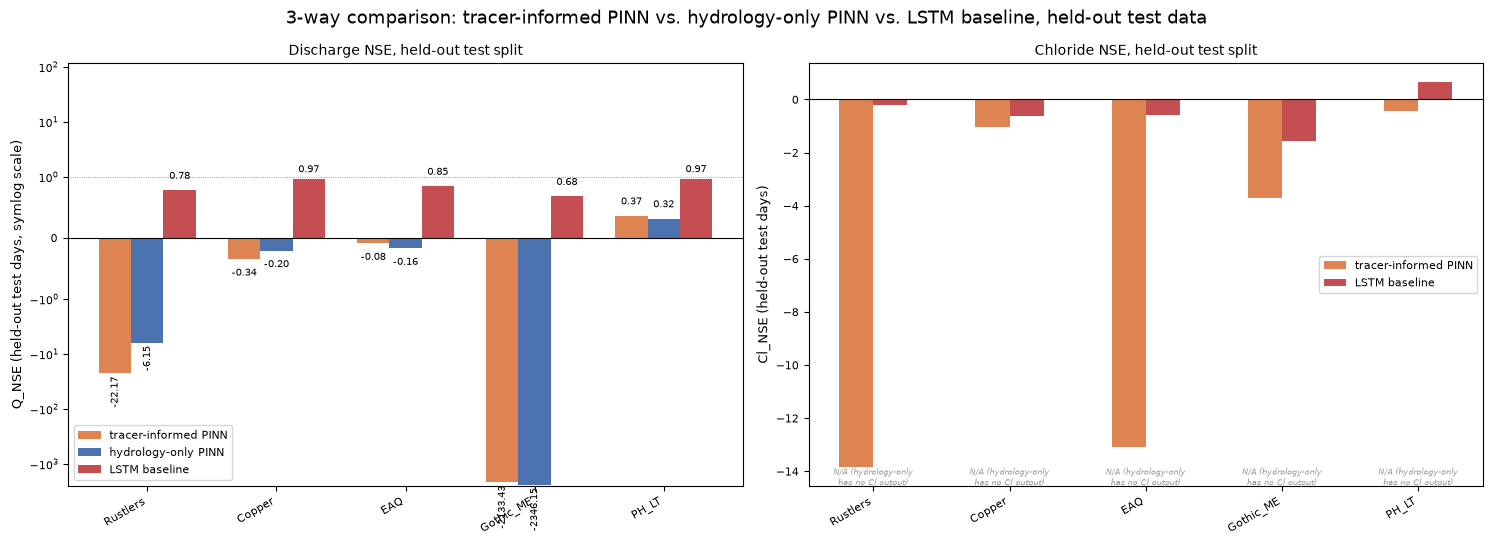

In [ ]:
width = 0.25
q_tracer = [tracer_info["metrics"][b]["Q_NSE_test"] for b in ORDER_COMP]
q_hydro = [hydro_info["metrics"][b]["Q_NSE_test"] for b in ORDER_COMP]
q_lstm = [lstm_info["metrics"][b]["Q_NSE_test"] for b in ORDER_COMP]
cl_tracer = [tracer_info["metrics"][b]["Cl_NSE_test"] for b in ORDER_COMP]
cl_lstm = [lstm_info["metrics"][b]["Cl_NSE_test"] for b in ORDER_COMP]

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
ax = axes[0]
ax.bar(x_comp - width, q_tracer, width, label="tracer-informed PINN", color=C["split"])
ax.bar(x_comp, q_hydro, width, label="hydrology-only PINN", color=C["single"])
ax.bar(x_comp + width, q_lstm, width, label="LSTM baseline", color=C["highlight"])
ax.axhline(0, color="black", lw=0.8); ax.axhline(1, color="gray", lw=0.6, ls=":")
ax.set_yscale("symlog", linthresh=1.0)
ax.set_xticks(x_comp); ax.set_xticklabels(ORDER_COMP, rotation=30, ha="right")
ax.set_ylabel("Q_NSE (held-out test days, symlog scale)")
ax.set_title("Discharge NSE, held-out test split")
ax.legend(fontsize=FONT["legend"], loc="lower left")

def _label_bars(ax_, xs, vs):
    for xi, v in zip(xs, vs):
        offset = 0.15 * max(abs(v), 1.0)
        ax_.text(xi, v + (offset if v >= 0 else -offset), f"{v:.2f}", ha="center",
                 va="bottom" if v >= 0 else "top", fontsize=FONT["annot"] - 1, rotation=90 if abs(v) > 5 else 0)

_label_bars(ax, x_comp - width, q_tracer); _label_bars(ax, x_comp, q_hydro); _label_bars(ax, x_comp + width, q_lstm)

ax = axes[1]
ax.bar(x_comp - width / 2, cl_tracer, width, label="tracer-informed PINN", color=C["split"])
ax.bar(x_comp + width / 2, cl_lstm, width, label="LSTM baseline", color=C["highlight"])
ymin = min(min(cl_tracer), min(cl_lstm), 0)
for xi in x_comp:
    ax.text(xi, ymin, "N/A (hydrology-only\nhas no Cl output)", ha="center", va="top",
            fontsize=FONT["annot"] - 2, color="#999", style="italic")
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(x_comp); ax.set_xticklabels(ORDER_COMP, rotation=30, ha="right")
ax.set_ylabel("Cl_NSE (held-out test days)")
ax.set_title("Chloride NSE, held-out test split")
ax.legend(fontsize=FONT["legend"])

fig.suptitle("3-way comparison: tracer-informed PINN vs. hydrology-only PINN vs. LSTM baseline, held-out test data")
fig.tight_layout()
q_summary = "\n".join(f"- {b}: tracer PINN={qt:.2f}, hydrology-only PINN={qh:.2f}, LSTM={ql:.2f}" for b, qt, qh, ql in zip(ORDER_COMP, q_tracer, q_hydro, q_lstm))
cl_summary = "\n".join(f"- {b}: tracer PINN={ct:.2f}, LSTM={cl_:.2f}" for b, ct, cl_ in zip(ORDER_COMP, cl_tracer, cl_lstm))
savefig(fig, f"{OUT_DIR_COMP}/01_nse_comparison_holdout.png", f"""
**Headline 3-way comparison, held-out test data.** Q_NSE (left) and Cl_NSE
(right) computed ONLY on each gauge's held-out test-split days (split.py,
seed=42, fixed 80/20 split of each gauge's own observed days, shared
identically across all three models -- none of the three ever trained on
these specific days). Hydrology-only PINN has no trained chloride output
(Cin_fast/Cin_gw receive zero gradient when cl_weight=0; see Step-1 scoping
note) so it's omitted from the right panel entirely rather than shown with
a fabricated number.

**Discharge NSE, held-out:**
{q_summary}

**Chloride NSE, held-out:**
{cl_summary}
""")

## Figure 2 (comparative) -- Baseflow fraction: tracer PINN vs. hydrology-only PINN

The LSTM has no internal fast/slow reservoir state, so this diagnostic
(routed `Q_s,tot/Q_tot` against the Hubbard et al. benchmark band) is
structurally inapplicable to it, not just unreported -- illustrated by
only plotting the two PINN variants here.

wrote /home/user/New/figures_final/comparative_analysis/02_baseflow_fraction_comparison.png


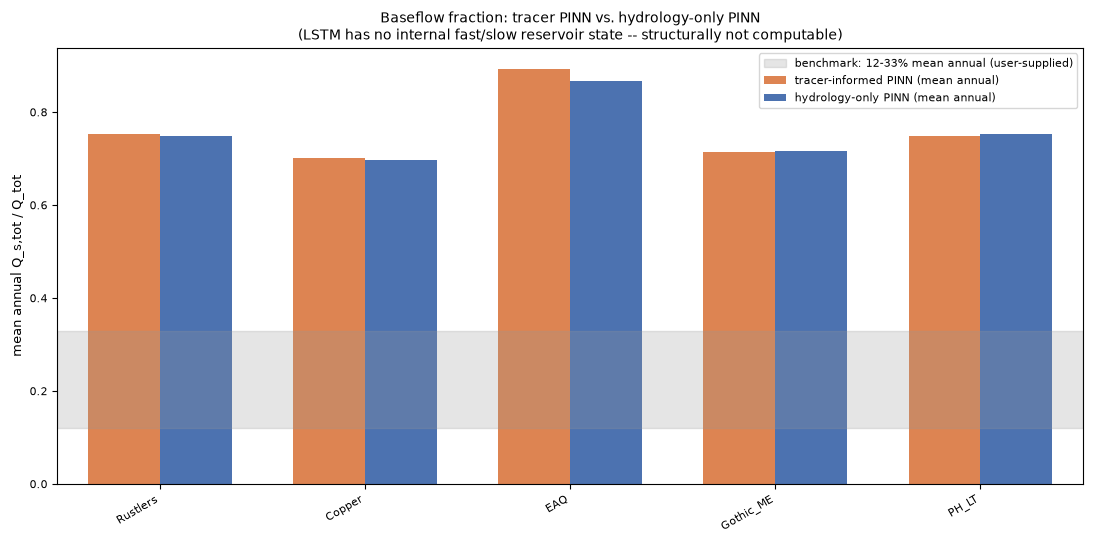

In [ ]:
HUBBARD_ANNUAL = (0.12, 0.33)
winter_mask_comp = dates_comp.month.isin([12, 1, 2, 3])

def baseflow_frac_comp(out_local, model_local):
    Quf = out_local["Quf"].numpy(); Qf = out_local["Qf"].numpy(); Qs = out_local["Qs"].numpy()
    area_cms = model_local.area_cms.numpy()
    routed = route({"Quf": Quf * area_cms, "Qf": Qf * area_cms, "Qs": Qs * area_cms})
    tot = routed["Quf"] + routed["Qf"] + routed["Qs"]
    return routed["Qs"] / np.clip(tot, 1e-9, None)

bf_tracer = baseflow_frac_comp(out_tracer, model_tracer)
bf_hydro = baseflow_frac_comp(out_hydro, model_hydro)

fig, ax = plt.subplots(figsize=(11, 5.5))
rows = []
for i, b in enumerate(ORDER_COMP):
    ma_t = float(np.nanmean(bf_tracer[:, i])); mb_t = float(np.nanmean(bf_tracer[winter_mask_comp, i]))
    ma_h = float(np.nanmean(bf_hydro[:, i])); mb_h = float(np.nanmean(bf_hydro[winter_mask_comp, i]))
    rows.append((b, ma_t, mb_t, ma_h, mb_h))
width2 = 0.35
ax.bar(x_comp - width2 / 2, [r[1] for r in rows], width2, label="tracer-informed PINN (mean annual)", color=C["split"])
ax.bar(x_comp + width2 / 2, [r[3] for r in rows], width2, label="hydrology-only PINN (mean annual)", color=C["single"])
ax.fill_between([-0.5, len(ORDER_COMP) - 0.5], HUBBARD_ANNUAL[0], HUBBARD_ANNUAL[1], color=C["benchmark"], alpha=0.25, label="benchmark: 12-33% mean annual (user-supplied)")
ax.set_xlim(-0.5, len(ORDER_COMP) - 0.5)
ax.set_xticks(x_comp); ax.set_xticklabels(ORDER_COMP, rotation=30, ha="right")
ax.set_ylabel("mean annual Q_s,tot / Q_tot")
ax.set_title("Baseflow fraction: tracer PINN vs. hydrology-only PINN\n(LSTM has no internal fast/slow reservoir state -- structurally not computable)")
ax.legend(fontsize=FONT["legend"])
fig.tight_layout()
bf_summary = "\n".join(f"- {b}: tracer PINN {ma_t:.1%} annual / {mb_t:.1%} winter, hydrology-only PINN {ma_h:.1%} annual / {mb_h:.1%} winter" for b, ma_t, mb_t, ma_h, mb_h in rows)
savefig(fig, f"{OUT_DIR_COMP}/02_baseflow_fraction_comparison.png", f"""
**Baseflow fraction: tracer PINN vs. hydrology-only PINN.** `Q_s,tot,j(t) /
Q_tot,j(t)`, ROUTED, both PINN variants (held-out-split checkpoints, this
round), against the same user-supplied Hubbard et al. (2018) benchmark
band used throughout `figures_final/core/08_baseflow_fraction_validation.png`
(that figure uses the original `results_meltlag_*` checkpoints; this one
uses this round's held-out-split retrains for a fair footing against the
LSTM). **The LSTM baseline has no fast/slow reservoir state at all** -- it
predicts Q and Cl directly with no internal hydrologic partitioning, so
this diagnostic is not just "not computed," it is structurally
inapplicable to that model by construction. This is a concrete illustration
of what physical interpretability buys beyond raw prediction accuracy: even
if the LSTM matched or beat the PINNs on NSE, it could never be checked
against this kind of independent, non-fitted-to benchmark.

**Result** (mean annual / mean winter baseflow fraction):
{bf_summary}
""")

## Figure 3 (comparative) -- Isotope cross-validation: tracer PINN vs. hydrology-only PINN

Same structural-inapplicability point as figure 2, for the isotope
d-excess cross-check instead of the baseflow benchmark.

wrote /home/user/New/figures_final/comparative_analysis/03_isotope_crossval_comparison.png


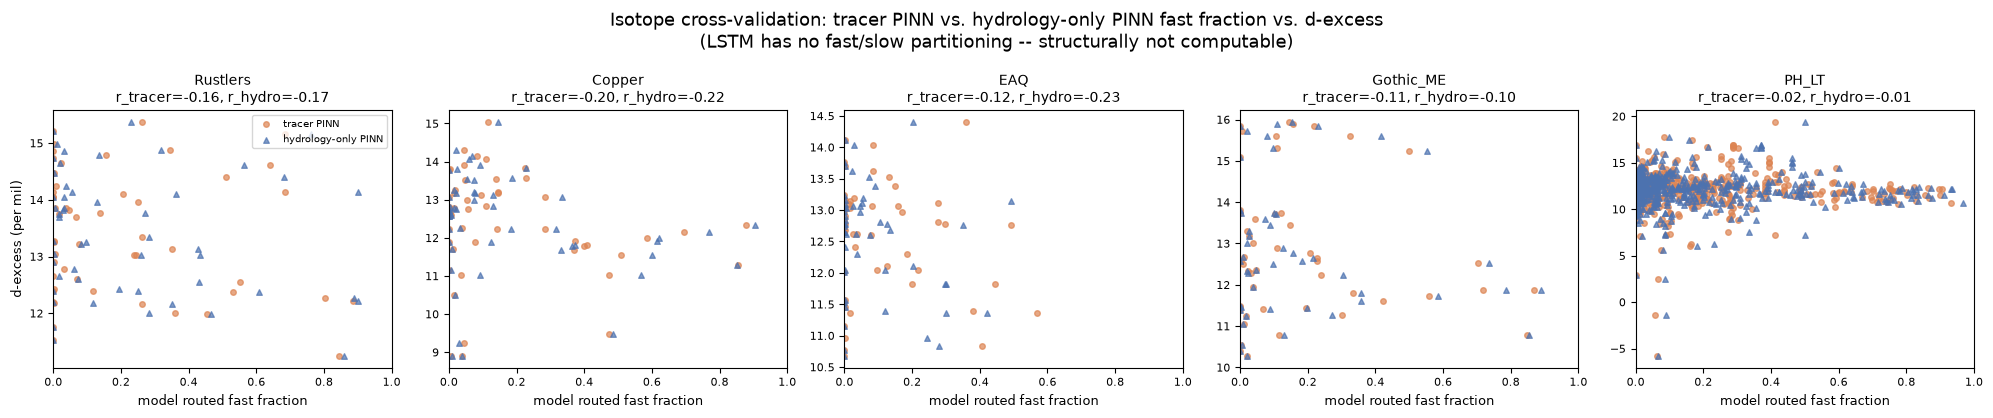

In [ ]:
iso_comp = pd.read_csv(f"{DATA_DIR}/isotopes_5subbasins_long.csv")
iso_comp["date"] = pd.to_datetime(iso_comp["date"])

def fast_frac_routed_comp(out_local, model_local):
    Quf = out_local["Quf"].numpy(); Qf = out_local["Qf"].numpy(); Qs = out_local["Qs"].numpy()
    area_cms = model_local.area_cms.numpy()
    routed = route({"Quf": Quf * area_cms, "Qf": Qf * area_cms, "Qs": Qs * area_cms})
    tot = routed["Quf"] + routed["Qf"] + routed["Qs"]
    return (routed["Quf"] + routed["Qf"]) / np.clip(tot, 1e-9, None)

ff_tracer = fast_frac_routed_comp(out_tracer, model_tracer)
ff_hydro = fast_frac_routed_comp(out_hydro, model_hydro)
ff_tracer_df = pd.DataFrame(ff_tracer, index=dates_comp, columns=ORDER_COMP)
ff_hydro_df = pd.DataFrame(ff_hydro, index=dates_comp, columns=ORDER_COMP)

fig, axes = plt.subplots(1, len(ORDER_COMP), figsize=(4 * len(ORDER_COMP), 4.2))
corr_rows = []
for i, b in enumerate(ORDER_COMP):
    ax = axes[i]
    sub = iso_comp[iso_comp["sub_basin"] == b].copy()
    sub["ff_tracer"] = sub["date"].map(ff_tracer_df[b]); sub["ff_hydro"] = sub["date"].map(ff_hydro_df[b])
    sub_t = sub.dropna(subset=["ff_tracer", "d_excess"]); sub_h = sub.dropna(subset=["ff_hydro", "d_excess"])
    r_t = np.corrcoef(sub_t["ff_tracer"], sub_t["d_excess"])[0, 1] if len(sub_t) >= 3 else float("nan")
    r_h = np.corrcoef(sub_h["ff_hydro"], sub_h["d_excess"])[0, 1] if len(sub_h) >= 3 else float("nan")
    ax.scatter(sub_t["ff_tracer"], sub_t["d_excess"], s=16, alpha=0.7, color=C["split"], label="tracer PINN")
    ax.scatter(sub_h["ff_hydro"], sub_h["d_excess"], s=16, alpha=0.7, color=C["single"], marker="^", label="hydrology-only PINN")
    ax.set_xlabel("model routed fast fraction"); ax.set_xlim(0, 1)
    if i == 0:
        ax.set_ylabel("d-excess (per mil)"); ax.legend(fontsize=FONT["legend"] - 1, loc="upper right")
    ax.set_title(f"{b}\nr_tracer={r_t:.2f}, r_hydro={r_h:.2f}", fontsize=FONT["title"])
    corr_rows.append((b, r_t, r_h, len(sub_t)))
fig.suptitle("Isotope cross-validation: tracer PINN vs. hydrology-only PINN fast fraction vs. d-excess\n(LSTM has no fast/slow partitioning -- structurally not computable)")
fig.tight_layout()
iso_summary = "\n".join(f"- {b}: r_tracer={rt:.2f}, r_hydro={rh:.2f} (n={n})" for b, rt, rh, n in corr_rows)
savefig(fig, f"{OUT_DIR_COMP}/03_isotope_crossval_comparison.png", f"""
**Isotope cross-validation, tracer PINN vs. hydrology-only PINN** (exploratory
-- same caveat as `figures_final/core/11_isotope_cross_validation.png`:
d-excess reflects source-water isotopic/evaporation history, not literally
"fraction fast vs. slow flow"; this is a consistency check, not a validated
quantitative test). Both PINN variants produce a routed fast-flow fraction
even without training on chloride (the partition network is trained
against discharge alone in the hydrology-only case), so this comparison
isolates what the *tracer* specifically adds to fast/slow partitioning,
separate from what physics-based routing alone provides. **The LSTM has no
equivalent output at all** -- another concrete case where physical
structure enables a check that a black-box model cannot be subjected to,
regardless of its raw accuracy.

**Correlation (Pearson r) between routed fast fraction and d-excess:**
{iso_summary}
""")

## Figure 5 (comparative) -- LSTM capacity ablation

Generated before figure 4 (the summary table) since the summary table
doesn't depend on it, matching the original script's order. Tests
whether the chloride held-out collapse in figure 1 is about this
particular LSTM's size or about data scarcity (38-43 Cl observations at
4 of 5 gauges): a second LSTM, hidden=16 (2,090 params, ~10x fewer),
trained under the identical held-out split. See FINDINGS.md Section 11.3
for the full result and interpretation.

wrote /home/user/New/figures_final/comparative_analysis/05_lstm_capacity_ablation.png


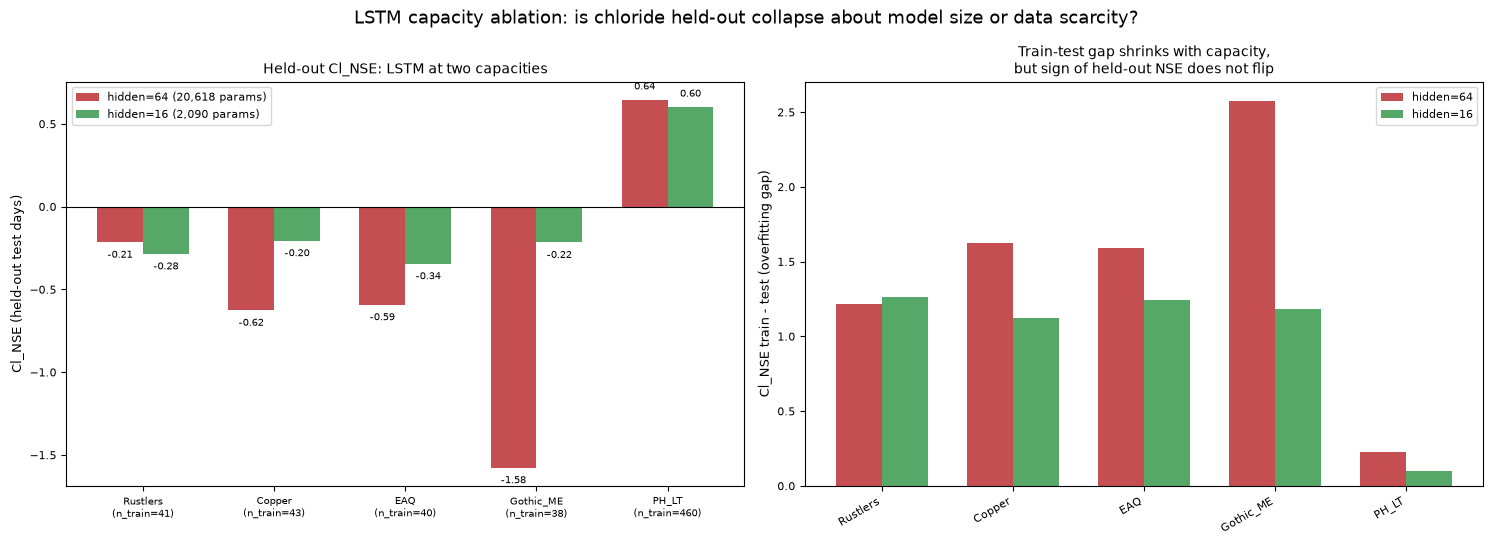

In [ ]:
cl_test_64 = [lstm_info["metrics"][b]["Cl_NSE_test"] for b in ORDER_COMP]
cl_test_16 = [lstm_small_info["metrics"][b]["Cl_NSE_test"] for b in ORDER_COMP]
gap_64 = [lstm_info["metrics"][b]["Cl_NSE_train"] - lstm_info["metrics"][b]["Cl_NSE_test"] for b in ORDER_COMP]
gap_16 = [lstm_small_info["metrics"][b]["Cl_NSE_train"] - lstm_small_info["metrics"][b]["Cl_NSE_test"] for b in ORDER_COMP]
n_cl_train = [tracer_info["metrics"][b]["n_Clobs_train"] for b in ORDER_COMP]

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
width3 = 0.35
ax = axes[0]
ax.bar(x_comp - width3 / 2, cl_test_64, width3, label="hidden=64 (20,618 params)", color=C["highlight"])
ax.bar(x_comp + width3 / 2, cl_test_16, width3, label="hidden=16 (2,090 params)", color=C["Cin_fast"])
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(x_comp); ax.set_xticklabels([f"{b}\n(n_train={n})" for b, n in zip(ORDER_COMP, n_cl_train)], fontsize=FONT["tick"] - 1)
ax.set_ylabel("Cl_NSE (held-out test days)")
ax.set_title("Held-out Cl_NSE: LSTM at two capacities")
ax.legend(fontsize=FONT["legend"])
for xi, v in zip(x_comp - width3 / 2, cl_test_64):
    ax.text(xi, v + (0.05 if v >= 0 else -0.05), f"{v:.2f}", ha="center", va="bottom" if v >= 0 else "top", fontsize=FONT["annot"] - 1)
for xi, v in zip(x_comp + width3 / 2, cl_test_16):
    ax.text(xi, v + (0.05 if v >= 0 else -0.05), f"{v:.2f}", ha="center", va="bottom" if v >= 0 else "top", fontsize=FONT["annot"] - 1)

ax = axes[1]
ax.bar(x_comp - width3 / 2, gap_64, width3, label="hidden=64", color=C["highlight"])
ax.bar(x_comp + width3 / 2, gap_16, width3, label="hidden=16", color=C["Cin_fast"])
ax.set_xticks(x_comp); ax.set_xticklabels(ORDER_COMP, rotation=30, ha="right")
ax.set_ylabel("Cl_NSE train - test (overfitting gap)")
ax.set_title("Train-test gap shrinks with capacity,\nbut sign of held-out NSE does not flip")
ax.legend(fontsize=FONT["legend"])

fig.suptitle("LSTM capacity ablation: is chloride held-out collapse about model size or data scarcity?")
fig.tight_layout()
ablation_summary = "\n".join(f"- {b} (n_Cl_train={n}): hidden=64 test={c64:.2f} (gap={g64:.2f}), hidden=16 test={c16:.2f} (gap={g16:.2f})"
                              for b, n, c64, g64, c16, g16 in zip(ORDER_COMP, n_cl_train, cl_test_64, gap_64, cl_test_16, gap_16))
savefig(fig, f"{OUT_DIR_COMP}/05_lstm_capacity_ablation.png", f"""
**LSTM capacity ablation.** Tests whether the chloride held-out collapse
in figure 1 is a function of this particular LSTM's size (hidden=64,
20,618 params) or of data scarcity (38-43 chloride observations at 4 of
5 gauges, vs. 460 at PH_LT) -- trains a second LSTM, hidden=16 (2,090
params, ~10x fewer), same architecture otherwise, under the IDENTICAL
held-out split (`results_comparative_lstm_small`).

**Result: the failure persists in kind at all 4 sparse-Cl gauges even at
1/10th the parameters** -- held-out `Cl_NSE` stays negative at Rustlers,
Copper, EAQ, and Gothic_ME at both capacities, and only PH_LT (460
training days, an order of magnitude more data than the other four) is
positive at both. The train-test overfitting gap DOES shrink with lower
capacity (mean gap across the 4 sparse gauges: 1.75 at hidden=64, 1.20 at
hidden=16 -- capacity is not irrelevant to *how severely* the model
memorizes), but the qualitative outcome -- can this architecture achieve
positive held-out `Cl_NSE` from ~40 sparse observations -- does not
change. This is the more general, stronger form of the finding: this
isn't "this particular LSTM was oversized for the task," it's that a
sequence model with no informative prior needs materially more chloride
observations than 4 of these 5 gauges have, regardless of its own
capacity, to generalize on held-out days. Discharge, which is not
comparably sparse at any gauge, does not show the same pattern --
held-out `Q_NSE` at hidden=16 is comparable to (in 3/5 cases, better
than) hidden=64's.

**Full numbers:**
{ablation_summary}
""")

## Figure 4 (comparative) -- Summary table

Consolidates the headline numbers from figures 1-3 and 5, plus the
qualitative interpretability comparison: only the PINN variants expose
inspectable physical parameters and an internal fast/slow reservoir state;
the LSTM is a black box by construction.

wrote /home/user/New/figures_final/comparative_analysis/04_summary_table.png
All Part 4 comparative-analysis figures written.


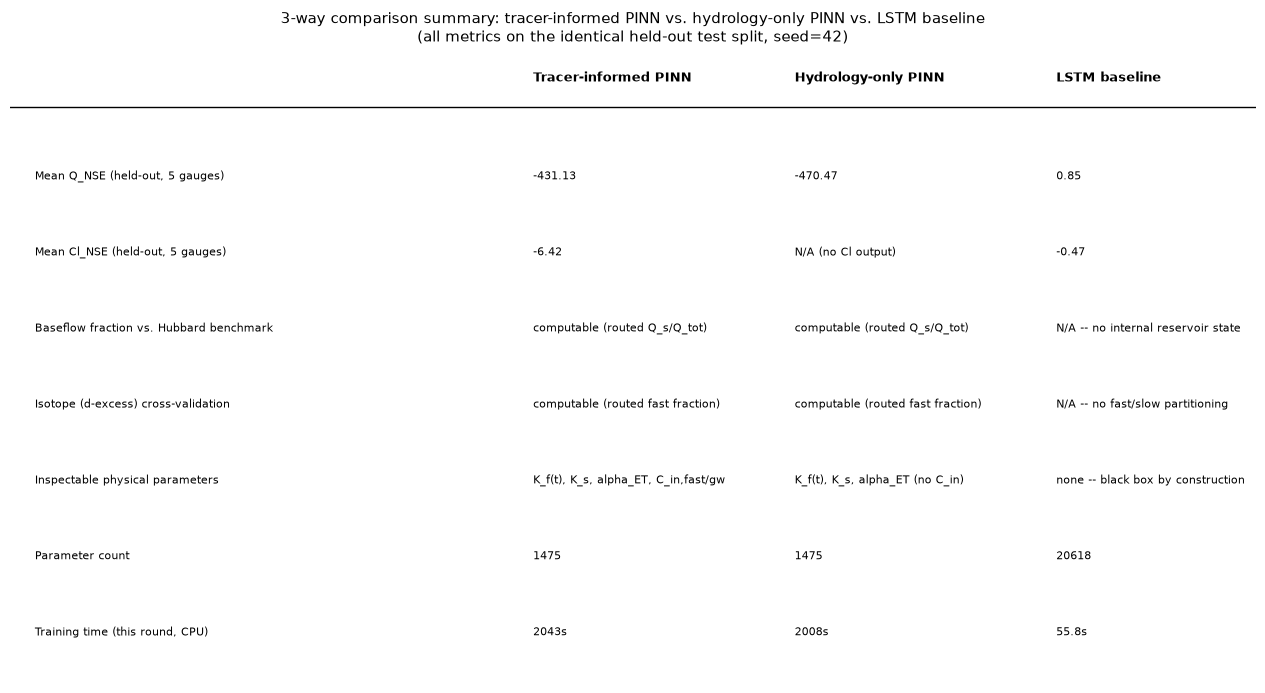

In [ ]:
mean_q_tracer = float(np.nanmean(q_tracer)); mean_q_hydro = float(np.nanmean(q_hydro)); mean_q_lstm = float(np.nanmean(q_lstm))
mean_cl_tracer = float(np.nanmean(cl_tracer)); mean_cl_lstm = float(np.nanmean(cl_lstm))

fig, ax = plt.subplots(figsize=(13, 7))
ax.axis("off")
rows_summary = [
    ("Mean Q_NSE (held-out, 5 gauges)", f"{mean_q_tracer:.2f}", f"{mean_q_hydro:.2f}", f"{mean_q_lstm:.2f}"),
    ("Mean Cl_NSE (held-out, 5 gauges)", f"{mean_cl_tracer:.2f}", "N/A (no Cl output)", f"{mean_cl_lstm:.2f}"),
    ("Baseflow fraction vs. Hubbard benchmark", "computable (routed Q_s/Q_tot)", "computable (routed Q_s/Q_tot)", "N/A -- no internal reservoir state"),
    ("Isotope (d-excess) cross-validation", "computable (routed fast fraction)", "computable (routed fast fraction)", "N/A -- no fast/slow partitioning"),
    ("Inspectable physical parameters", "K_f(t), K_s, alpha_ET, C_in,fast/gw", "K_f(t), K_s, alpha_ET (no C_in)", "none -- black box by construction"),
    ("Parameter count", f"{sum(p.numel() for p in model_tracer.parameters())}", f"{sum(p.numel() for p in model_hydro.parameters())}", f"{lstm_info['train_config']['n_params']}"),
    ("Training time (this round, CPU)", f"{tracer_info['train_config']['train_time_s']:.0f}s", f"{hydro_info['train_config']['train_time_s']:.0f}s", f"{lstm_info['train_config']['train_time_s']:.1f}s"),
]
col_x = [0.02, 0.42, 0.63, 0.84]
for xx, h in zip(col_x, ["", "Tracer-informed PINN", "Hydrology-only PINN", "LSTM baseline"]):
    ax.text(xx, 0.95, h, fontsize=FONT["label"], fontweight="bold", transform=ax.transAxes)
ax.plot([0.0, 1.0], [0.91, 0.91], color="black", lw=1.0, transform=ax.transAxes)
row_ys = np.linspace(0.80, 0.08, len(rows_summary))
for y, (label, vt, vh, vl) in zip(row_ys, rows_summary):
    ax.text(col_x[0], y, label, fontsize=FONT["annot"], va="center", transform=ax.transAxes, wrap=True)
    ax.text(col_x[1], y, vt, fontsize=FONT["annot"], va="center", transform=ax.transAxes)
    ax.text(col_x[2], y, vh, fontsize=FONT["annot"], va="center", transform=ax.transAxes)
    ax.text(col_x[3], y, vl, fontsize=FONT["annot"], va="center", transform=ax.transAxes)
ax.set_title("3-way comparison summary: tracer-informed PINN vs. hydrology-only PINN vs. LSTM baseline\n(all metrics on the identical held-out test split, seed=42)", fontsize=FONT["title"] + 1)
fig.tight_layout()
savefig(fig, f"{OUT_DIR_COMP}/04_summary_table.png", """
**3-way comparison summary.** Consolidates the headline numbers from
figures 1-3 plus the qualitative interpretability comparison the user
asked to have noted explicitly: only the two PINN variants expose
inspectable physical parameters (`K_f,j(t)`'s bounds, `K_s`, `alpha_ET`,
and -- tracer-informed only -- `C_in`) and only they have an internal
fast/slow reservoir state that the baseflow-fraction and isotope
cross-validation checks in figures 2-3 depend on; the LSTM is a black box
by construction and those two diagnostics are not just unreported for it,
they are structurally inapplicable. Parameter counts and training times
are included for scale: the LSTM has ~2 orders of magnitude fewer
parameters and trains in seconds rather than tens of minutes on this CPU
environment, reflecting that it fits a much less constrained function
(no closed-form ODE integration, no routing topology, no physical bounds)
to the same, small (737-day, sparse-Cl) dataset.
""")

print("All Part 4 comparative-analysis figures written.")